# Pós-Graduação em IA Aplicada
### Unidade Curricular: Machine Learning
**Professor:** Giancarlo Marchesini, Me.

---

# Previsão de Séries Temporais: o que muda em relação à regressão?

Você já sabe treinar uma regressão. Esta aula responde a uma pergunta prática: **se eu pegar uma série ao longo do tempo e aplicar uma regressão "de sempre", o que dá errado, e como corrijo?**

Vamos resolver **um único caso, do começo ao fim**, em passos curtos. Em cada passo, aparece uma armadilha que só existe porque os dados têm ordem no tempo.

**Formato:** 1 aula de 2h.

## O caso

> Você é analista de demanda de uma companhia aérea. O diretor pede a **previsão de passageiros dos próximos 24 meses** para planejar frota e tripulação. Você tem o histórico mensal de 12 anos.

| Módulo | Passo do caso | Tempo sugerido |
|---|---|---|
| 1 | Conhecer a série | 8 min |
| 2 | Entender a estrutura da série | 8 min |
| 3 | Combinar como avaliar a previsão | 10 min |
| 4 | A tentação: usar a regressão "normal" | 10 min |
| 5 | Lags e autocorrelação: dar memória ao modelo | 18 min |
| 6 | Algoritmos clássicos de regressão sobre os lags | 18 min |
| 7 | O problema da tendência: o que árvores e SVR não fazem | 8 min |
| 8 | O especialista: SARIMA e Holt-Winters (em resumo) | 12 min |
| 9 | Placar final e a diferença regressão x série temporal | 8 min |
| 10 | Pipeline de treino e inferência: as janelas | 15 min |
| 11 | Fechamento e exercícios | 5 min |

> ▶️ **Como usar no Google Colab:** `Arquivo > Fazer upload de notebook`, envie este `.ipynb` e execute as células **em ordem** (`Ambiente de execução > Executar tudo` também funciona). Os dados estão embutidos no notebook, então não é preciso baixar nada.

## Objetivos

Ao final da aula, vocês devem ser capazes de:

1. Explicar por que uma série temporal exige tratamento diferente de um dataset tabular.
2. Reconhecer tendência, sazonalidade e resíduo em uma série, e decidir quando usar o logaritmo.
3. Explicar o que são **lags** e **autocorrelação**, ler ACF e PACF, e **transformar uma série em uma tabela de atributos** para regressão.
4. Treinar **SVR, Random Forest e Gradient Boosting** sobre essa tabela e prever vários meses à frente (previsão recursiva).
5. Avaliar previsões com divisão temporal e compará-las com um baseline simples.
6. Montar um **pipeline de treino e inferência** e explicar o papel da **janela de treino**, da **série de entrada** e da **inferência**.
7. Conhecer, em resumo, SARIMA e Holt-Winters como alternativas especializadas.
8. Apontar, com exemplos, as diferenças entre uma regressão "normal" e uma previsão de série temporal.

## O dataset: *International Airline Passengers* (Box & Jenkins)

| Característica | Valor |
|---|---|
| Amostras | 144 observações mensais, de janeiro de 1949 a dezembro de 1960 |
| Variável | `passageiros`: total mensal de passageiros de companhias aéreas internacionais, em milhares |
| Valores faltantes | Nenhum |
| Fonte | Box, G. E. P., Jenkins, G. M. e Reinsel, G. C. *Time Series Analysis, Forecasting and Control* (Série G). Um dos conjuntos mais clássicos da área, embutido neste notebook |

É um dataset pequeno e limpo de propósito: reúne, em uma única série, o que mais aparece em dados reais de transporte, vendas e consumo, que é **crescimento ao longo dos anos**, **um padrão que se repete todo ano** e **oscilações que crescem junto com o nível**.

In [ ]:
# Bibliotecas usadas ao longo da aula
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Avisos de convergencia dos modelos estatisticos sao esperados nesta aula; silenciamos para manter a saida limpa.
warnings.filterwarnings("ignore")

SEMENTE = 42
H = 24  # horizonte da previsao: os ultimos 24 meses ficam reservados para teste
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


def metricas(y_real, y_prev):
    """MAE e RMSE (em milhares de passageiros) e MAPE (erro percentual medio)."""
    y_real, y_prev = np.asarray(y_real, dtype=float), np.asarray(y_prev, dtype=float)
    return {
        "MAE": mean_absolute_error(y_real, y_prev),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_prev)),
        "MAPE (%)": np.mean(np.abs((y_real - y_prev) / y_real)) * 100,
    }


print("Bibliotecas prontas.")

Bibliotecas prontas.


# Módulo 1 — Conhecer a série

> 🎯 **Objetivo:** carregar a série e entender, com um experimento simples, por que a ordem dos dados muda tudo.

**No caso:** primeiro passo de qualquer análise, olhar os dados.

## 1.1 Carregando

Uma **série temporal** é uma sequência de valores medidos ao longo do tempo, em intervalos regulares (aqui, todo mês). O que transforma uma lista de números em uma série é o **índice de datas**.

144 meses, de 01/1949 a 12/1960 | valores nulos: 0


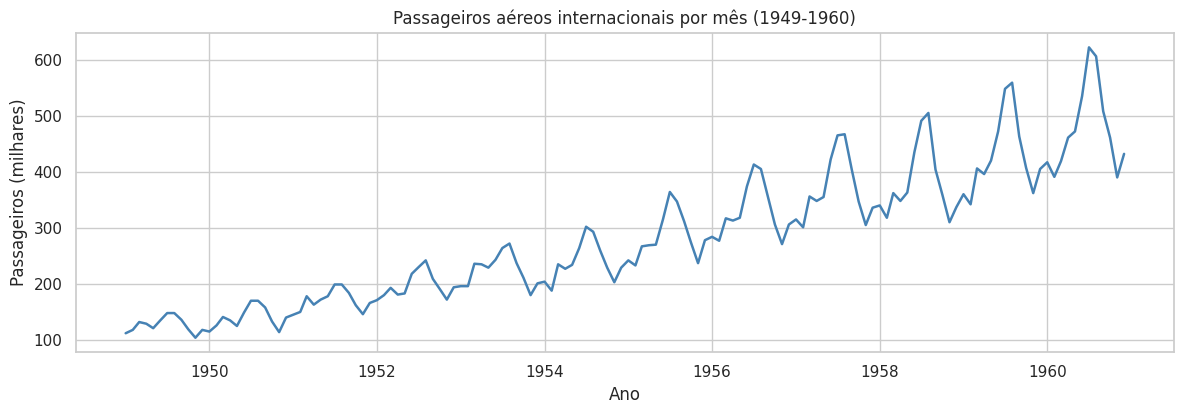

In [ ]:
passageiros = [
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432,
]

indice = pd.date_range(start="1949-01-01", periods=len(passageiros), freq="MS")  # MS = inicio de cada mes
serie = pd.Series(passageiros, index=indice, name="passageiros")

print(f"{len(serie)} meses, de {serie.index.min():%m/%Y} a {serie.index.max():%m/%Y} | valores nulos: {serie.isna().sum()}")

plt.figure(figsize=(12, 4.3))
plt.plot(serie, color="steelblue", linewidth=1.8)
plt.title("Passageiros aéreos internacionais por mês (1949-1960)")
plt.xlabel("Ano"); plt.ylabel("Passageiros (milhares)")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** Três coisas saltam aos olhos: o nível **sobe** ao longo dos anos (tendência), existe um **padrão que se repete todo ano** (picos no meio do ano, vales no fim) e as oscilações **ficam cada vez maiores** conforme o nível sobe.

## 1.2 O teste do embaralhamento

Em um dataset tabular, embaralhar as linhas não muda nada. Veja o que acontece aqui.

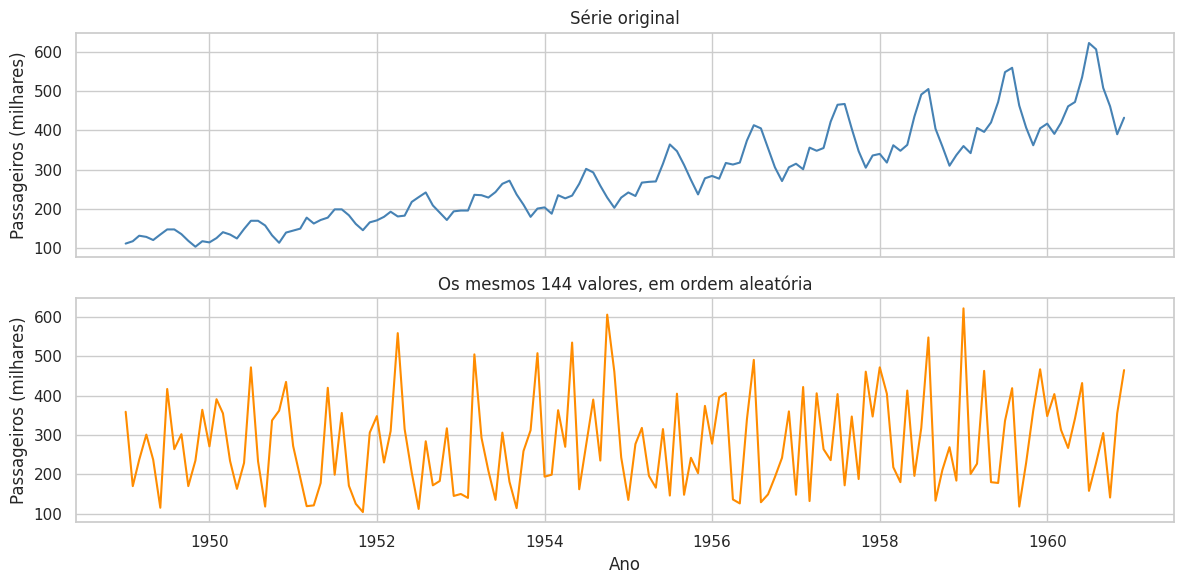

Média e desvio padrão: original = 280.3 e 120.0 | embaralhada = 280.3 e 120.0
Correlação de cada mês com o mês anterior: original = 0.96 | embaralhada = -0.05


In [ ]:
rng = np.random.RandomState(SEMENTE)
serie_embaralhada = pd.Series(rng.permutation(serie.values), index=serie.index)

figura, eixos = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
eixos[0].plot(serie, color="steelblue"); eixos[0].set_title("Série original")
eixos[1].plot(serie_embaralhada, color="darkorange"); eixos[1].set_title("Os mesmos 144 valores, em ordem aleatória")
eixos[1].set_xlabel("Ano")
for eixo in eixos:
    eixo.set_ylabel("Passageiros (milhares)")
plt.tight_layout()
plt.show()

print(f"Média e desvio padrão: original = {serie.mean():.1f} e {serie.std():.1f} | embaralhada = {serie_embaralhada.mean():.1f} e {serie_embaralhada.std():.1f}")
print(f"Correlação de cada mês com o mês anterior: original = {serie.autocorr(lag=1):.2f} | embaralhada = {serie_embaralhada.autocorr(lag=1):.2f}")

> 💡 **Analogia.** Uma série temporal é um **filme**, não uma foto. Embaralhar os quadros preserva as imagens (a média e o desvio são os mesmos), mas destrói a história. As estatísticas "de tabela" não enxergam isso, porque ignoram a ordem.

> 📌 **Leitura.** Na série original, cada mês se parece muito com o anterior (correlação perto de 1); na embaralhada, essa relação some. Essa **dependência no tempo** é o que os modelos de série temporal aproveitam, e é justamente ela que quebra as hipóteses de uma regressão comum. Vamos ver isso acontecer nos próximos módulos.

# Módulo 2 — Entender a estrutura da série

> 🎯 **Objetivo:** separar a série em camadas (tendência, sazonalidade, resto) e decidir se vamos modelar o valor ou o logaritmo.

**No caso:** antes de prever, precisamos saber **o que** estamos prevendo.

## 2.1 Cada ano é uma cópia do anterior, só que mais alto

Sobrepor os anos no mesmo eixo de meses mostra se o padrão sazonal é estável.

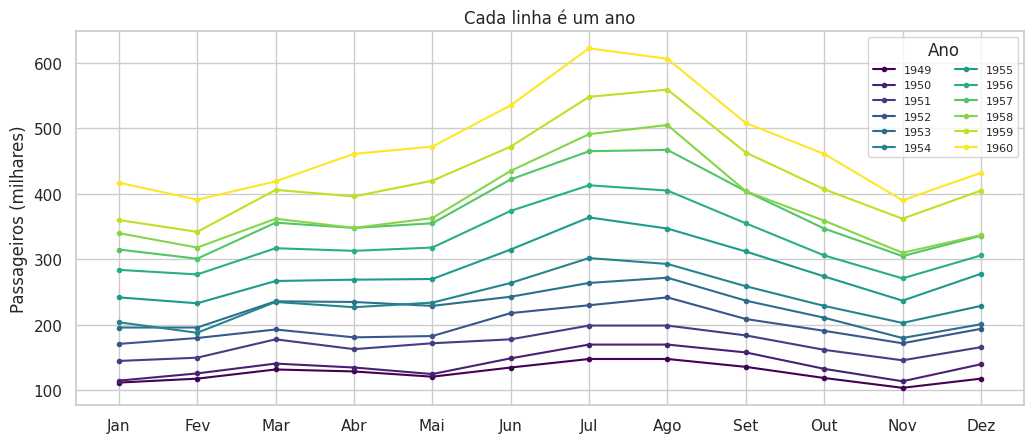

In [ ]:
df_serie = serie.to_frame()
df_serie["ano"], df_serie["mes"] = df_serie.index.year, df_serie.index.month
tabela_ano_mes = df_serie.pivot_table(values="passageiros", index="mes", columns="ano")

plt.figure(figsize=(10.5, 4.6))
cores = plt.cm.viridis(np.linspace(0, 1, tabela_ano_mes.shape[1]))
for cor, ano in zip(cores, tabela_ano_mes.columns):
    plt.plot(tabela_ano_mes.index, tabela_ano_mes[ano], color=cor, marker="o", markersize=3, label=str(ano))
plt.xticks(range(1, 13), ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"])
plt.ylabel("Passageiros (milhares)"); plt.title("Cada linha é um ano")
plt.legend(ncol=2, fontsize=8, title="Ano")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** As 12 linhas têm praticamente a **mesma forma** (pico em julho e agosto, vale em novembro), mas estão em **alturas diferentes**: cada ano começa mais alto que o anterior.

## 2.2 Separando em três camadas

> 💡 **Analogia.** Pense na sua **conta de luz**. Ela tem um nível que vai subindo com os anos (a **tendência**), um padrão que se repete (mais alta no verão por causa do ar-condicionado: a **sazonalidade**) e uma sobra imprevisível de mês a mês (o **resíduo**). Decompor a série é separar essas três camadas.

Como a oscilação cresce junto com o nível, a sazonalidade aqui é **multiplicativa**: o pico de julho não soma um valor fixo, ele **multiplica** o nível ("julho é 20% acima do normal").

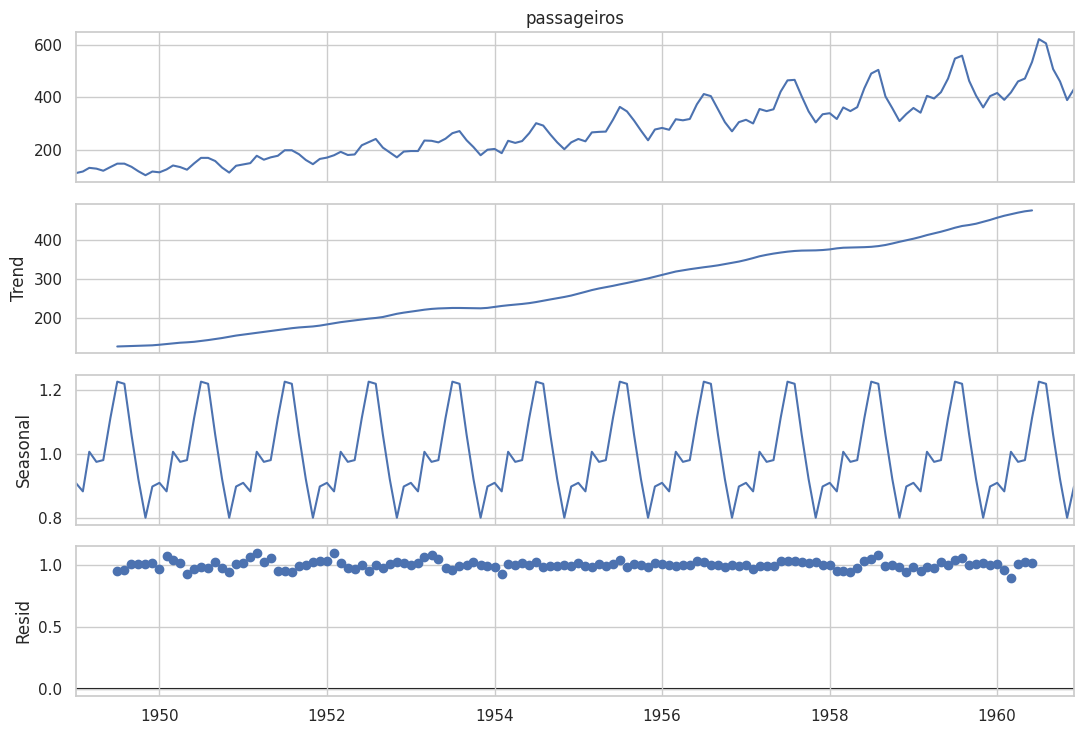

Fator sazonal de julho: 1.23 (cerca de 23% acima da tendência)
Fator sazonal de novembro: 0.80 (cerca de 20% abaixo da tendência)


In [ ]:
decomposicao = seasonal_decompose(serie, model="multiplicative", period=12)
figura = decomposicao.plot()
figura.set_size_inches(11, 7.5)
plt.tight_layout()
plt.show()

fatores = decomposicao.seasonal.iloc[:12]
print(f"Fator sazonal de julho: {fatores.iloc[6]:.2f} (cerca de {100 * (fatores.iloc[6] - 1):.0f}% acima da tendência)")
print(f"Fator sazonal de novembro: {fatores.iloc[10]:.2f} (cerca de {100 * (1 - fatores.iloc[10]):.0f}% abaixo da tendência)")

> 📌 **Leitura.** De cima para baixo: a série, a **tendência** (curva crescente suave), a **sazonalidade** (o mesmo desenho todo ano) e o **resíduo** (o que sobrou, sem padrão óbvio). Essa é a "receita" da série: um modelo bom precisa reproduzir tendência **e** sazonalidade.

## 2.3 Por que vamos modelar o logaritmo

Se a oscilação cresce junto com o nível, o logaritmo "comprime" os valores grandes e deixa a amplitude parecida do começo ao fim da série.

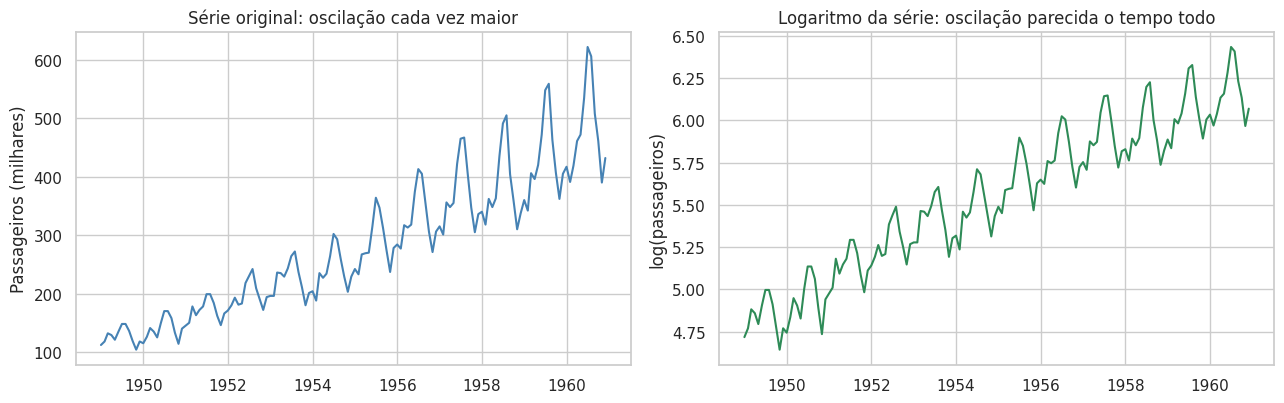

Desvio padrão do último ano dividido pelo do primeiro -> original: 5.7x | em log: 1.4x


In [ ]:
por_ano = serie.groupby(serie.index.year).std()
por_ano_log = np.log(serie).groupby(serie.index.year).std()

figura, eixos = plt.subplots(1, 2, figsize=(13, 4.2))
eixos[0].plot(serie, color="steelblue"); eixos[0].set_title("Série original: oscilação cada vez maior")
eixos[1].plot(np.log(serie), color="seagreen"); eixos[1].set_title("Logaritmo da série: oscilação parecida o tempo todo")
eixos[0].set_ylabel("Passageiros (milhares)"); eixos[1].set_ylabel("log(passageiros)")
plt.tight_layout()
plt.show()

print(f"Desvio padrão do último ano dividido pelo do primeiro -> original: {por_ano.iloc[-1] / por_ano.iloc[0]:.1f}x | em log: {por_ano_log.iloc[-1] / por_ano_log.iloc[0]:.1f}x")

> 📌 **Leitura.** Na escala original, a oscilação do último ano é mais de **5 vezes** a do primeiro; em log, fica em torno de **1,4 vez**. Por isso, nos modelos que vêm a seguir, trabalhamos com `log(passageiros)` e, no final, voltamos à escala original com `exp`.

# Módulo 3 — Combinar como avaliar a previsão

> 🎯 **Objetivo:** definir a "prova" a que todo modelo será submetido e o piso que ele precisa superar.

**No caso:** antes de treinar qualquer modelo, combinamos as regras do jogo. Trocar a regra depois, quando já vimos os resultados, é trapaça.

## 3.1 A prova não pode ter cola do futuro

Em regressão comum, sorteamos linhas para teste. Em série temporal, isso é erro grave por dois motivos: o modelo treinaria com meses **posteriores** ao que vai prever (impossível na vida real) e prever um mês "no meio" da série, conhecendo os vizinhos dos dois lados, é **interpolar**, muito mais fácil que **prever**.

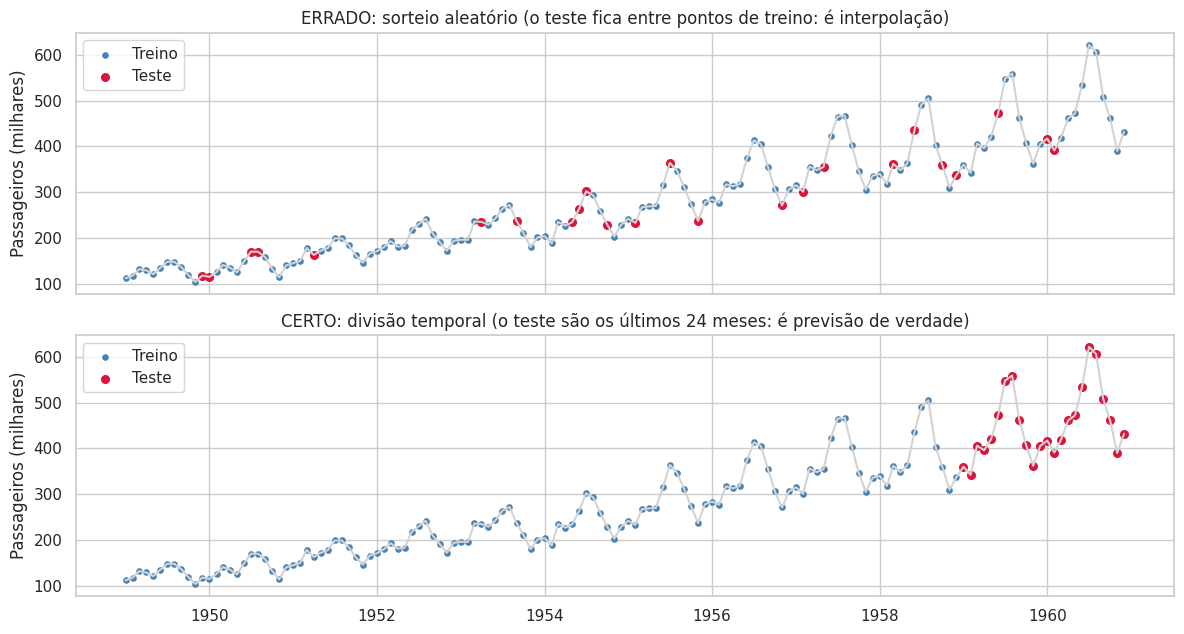

In [ ]:
indices = np.arange(len(serie))
idx_treino_alea, idx_teste_alea = train_test_split(indices, test_size=H, random_state=SEMENTE)

figura, eixos = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
eixos[0].plot(serie, color="lightgray")
eixos[0].scatter(serie.index[idx_treino_alea], serie.values[idx_treino_alea], color="steelblue", s=14, label="Treino")
eixos[0].scatter(serie.index[idx_teste_alea], serie.values[idx_teste_alea], color="crimson", s=30, label="Teste")
eixos[0].set_title("ERRADO: sorteio aleatório (o teste fica entre pontos de treino: é interpolação)")
eixos[1].plot(serie, color="lightgray")
eixos[1].scatter(serie.index[:-H], serie.values[:-H], color="steelblue", s=14, label="Treino")
eixos[1].scatter(serie.index[-H:], serie.values[-H:], color="crimson", s=30, label="Teste")
eixos[1].set_title(f"CERTO: divisão temporal (o teste são os últimos {H} meses: é previsão de verdade)")
for eixo in eixos:
    eixo.set_ylabel("Passageiros (milhares)"); eixo.legend(loc="upper left")
plt.tight_layout()
plt.show()

> 💡 **Analogia.** É a diferença entre fazer uma prova com o **gabarito do futuro** escondido e uma prova em que você pode **colar** do que ainda não aconteceu. Na vida real, ninguém conhece o futuro, então a avaliação também não pode conhecer.

## 3.2 A regra do jogo

Treinamos com 1949 a 1958 (120 meses) e testamos em 1959 e 1960 (24 meses). Medimos o erro de três formas, todas fáceis de explicar a um diretor:

- **MAE:** em média, quantos milhares de passageiros o modelo erra por mês.
- **RMSE:** parecido com o MAE, mas castiga mais os erros grandes.
- **MAPE:** erro médio em porcentagem do valor real. É o mais fácil de comunicar ("erramos 7% em média"). Vamos usá-lo como principal.

In [ ]:
treino, teste = serie.iloc[:-H], serie.iloc[-H:]
print(f"Treino: {treino.index.min():%m/%Y} a {treino.index.max():%m/%Y} ({len(treino)} meses)")
print(f"Teste : {teste.index.min():%m/%Y} a {teste.index.max():%m/%Y} ({len(teste)} meses)")

# Dicionarios onde guardamos previsoes e metricas de TODOS os modelos, para o placar final (Modulo 9)
resultados, previsoes = {}, {}


def registrar(nome, previsao):
    """Guarda a previsao (alinhada ao indice do teste) e suas metricas."""
    previsao = pd.Series(np.asarray(previsao, dtype=float), index=teste.index)
    previsoes[nome] = previsao
    resultados[nome] = metricas(teste, previsao)
    return resultados[nome]


def plotar_previsao(titulo, previsao, intervalo=None, eixo=None, n_historico=48):
    """Treino (ultimos meses), teste real, previsao e, opcionalmente, o intervalo de confianca."""
    if eixo is None:
        plt.figure(figsize=(12, 4.5)); eixo = plt.gca()
    eixo.plot(treino.iloc[-n_historico:], color="steelblue", label="Treino")
    eixo.plot(teste, color="black", linewidth=2, label="Real (teste)")
    eixo.plot(previsao, color="crimson", linestyle="--", marker="o", markersize=3, label="Previsão")
    if intervalo is not None:
        eixo.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1], color="crimson", alpha=0.15, label="IC 95%")
    eixo.set_title(titulo); eixo.set_ylabel("Passageiros (milhares)"); eixo.legend(loc="upper left", fontsize=8)

Treino: 01/1949 a 12/1958 (120 meses)
Teste : 01/1959 a 12/1960 (24 meses)


## 3.3 O piso: previsões ingênuas

Antes de qualquer modelo sofisticado, calculamos previsões **triviais**. Se um modelo complexo não ganha delas, ele não vale o esforço.

- **Naive:** repete o último valor observado ("amanhã vai ser igual a hoje").
- **Naive sazonal:** repete o mesmo mês do ano anterior ("dezembro de 1959 vai ser igual a dezembro de 1958").
- **Drift:** continua a inclinação média histórica em linha reta.

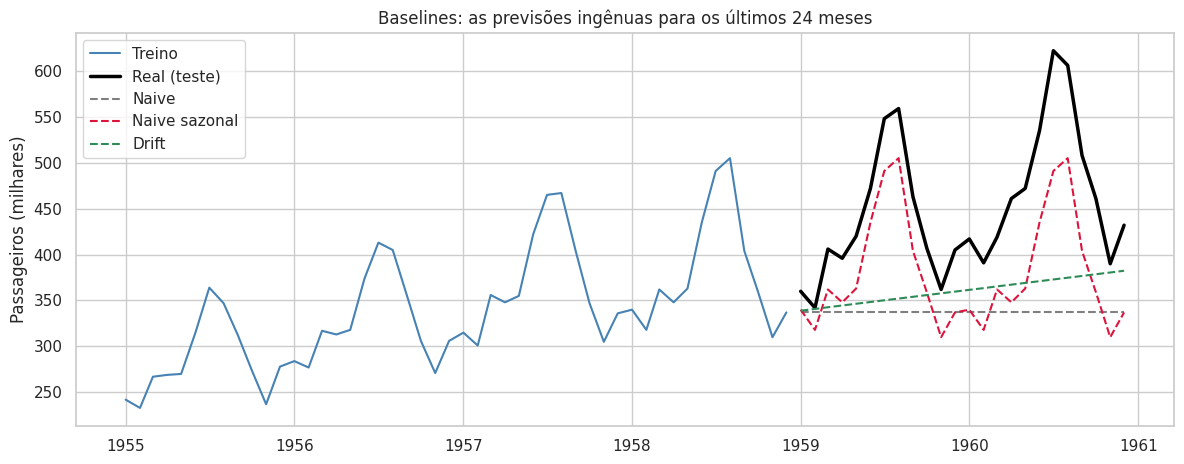

,MAE,RMSE,MAPE (%)
Naive,115.25,137.33,23.58
Naive sazonal,71.25,76.99,15.52
Drift,91.62,115.70,18.41


In [ ]:
naive = np.full(H, treino.iloc[-1])
naive_sazonal = np.tile(treino.iloc[-12:].values, H // 12)
inclinacao = (treino.iloc[-1] - treino.iloc[0]) / (len(treino) - 1)
drift = treino.iloc[-1] + inclinacao * np.arange(1, H + 1)

for nome, prev in [("Naive", naive), ("Naive sazonal", naive_sazonal), ("Drift", drift)]:
    registrar(nome, prev)

plt.figure(figsize=(12, 4.8))
plt.plot(treino.iloc[-48:], color="steelblue", label="Treino")
plt.plot(teste, color="black", linewidth=2.5, label="Real (teste)")
for nome, cor in [("Naive", "gray"), ("Naive sazonal", "crimson"), ("Drift", "seagreen")]:
    plt.plot(previsoes[nome], linestyle="--", color=cor, label=nome)
plt.title("Baselines: as previsões ingênuas para os últimos 24 meses")
plt.ylabel("Passageiros (milhares)"); plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

pd.DataFrame(resultados).T.round(2)

> 📌 **Leitura.** O **naive sazonal** é o melhor dos três: ele reconhece o ciclo anual, enquanto naive e drift o ignoram. Ele erra porque **não soma o crescimento**: repete o ano passado sem somar o aumento. Esse é o **número a bater**: qualquer modelo mais complexo precisa ficar claramente abaixo dele.

# Módulo 4 — A tentação: usar a regressão "normal"

> 🎯 **Objetivo:** aplicar uma regressão comum à série e descobrir, em dois experimentos, por que ela engana.

**No caso:** você já sabe fazer regressão, então a primeira ideia é usar o que conhece. Os atributos são "onde estamos no calendário": o número do mês na linha do tempo (`t`) e o mês do ano.

## 4.1 Experimento 1: o mesmo modelo, duas formas de avaliar

Treinamos dois modelos e avaliamos de dois jeitos: com **sorteio aleatório** (como em regressão comum) e com **divisão temporal** (como na vida real).

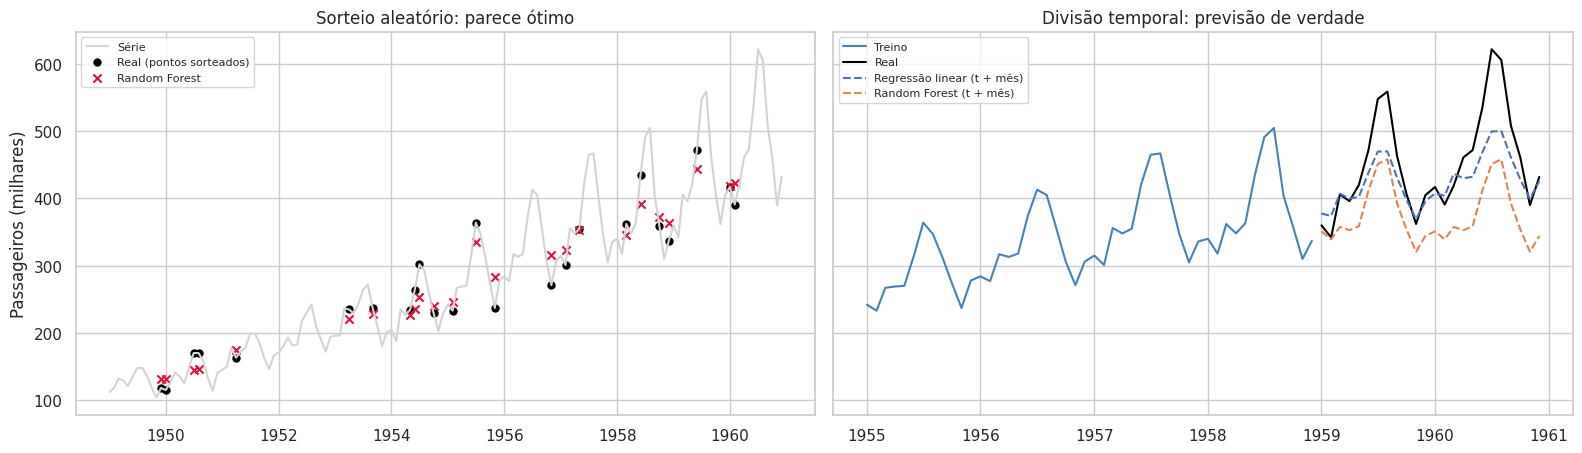

,MAE (sorteio aleatório),MAE (divisão temporal)
modelo,,
Regressão linear (t + mês),22.0,34.6
Random Forest (t + mês),21.9,77.9


In [ ]:
df_calendario = pd.DataFrame({"t": np.arange(len(serie)), "mes": serie.index.month, "y": serie.values}, index=serie.index)
X_cal, y_cal = df_calendario[["t", "mes"]], df_calendario["y"]


def pipeline_calendario(modelo):
    """O mes vira variavel categorica (one-hot); t segue como numero."""
    prep = ColumnTransformer([("mes", OneHotEncoder(handle_unknown="ignore"), ["mes"])], remainder="passthrough")
    return Pipeline([("prep", prep), ("modelo", modelo)])


idx_tr_alea, idx_te_alea = train_test_split(np.arange(len(serie)), test_size=H, random_state=SEMENTE)
modelos_calendario = {
    "Regressão linear (t + mês)": LinearRegression(),
    "Random Forest (t + mês)": RandomForestRegressor(n_estimators=300, random_state=SEMENTE),
}

linhas_calendario, prev_temporal_cal, prev_aleatoria_rf = [], {}, None
for nome, modelo in modelos_calendario.items():
    p = pipeline_calendario(clone(modelo)).fit(X_cal.iloc[idx_tr_alea], y_cal.iloc[idx_tr_alea])
    prev_alea = pd.Series(p.predict(X_cal.iloc[idx_te_alea]), index=serie.index[idx_te_alea])
    if "Forest" in nome:
        prev_aleatoria_rf = prev_alea
    mae_aleatorio = mean_absolute_error(y_cal.iloc[idx_te_alea], prev_alea)

    p = pipeline_calendario(clone(modelo)).fit(X_cal.iloc[:-H], y_cal.iloc[:-H])
    prev_temporal_cal[nome] = pd.Series(p.predict(X_cal.iloc[-H:]), index=teste.index)
    registrar(nome, prev_temporal_cal[nome])
    linhas_calendario.append({"modelo": nome, "MAE (sorteio aleatório)": mae_aleatorio, "MAE (divisão temporal)": resultados[nome]["MAE"]})

figura, eixos = plt.subplots(1, 2, figsize=(16, 4.7), sharey=True)
eixos[0].plot(serie, color="lightgray", label="Série")
eixos[0].scatter(prev_aleatoria_rf.index, serie.loc[prev_aleatoria_rf.index], color="black", s=25, label="Real (pontos sorteados)")
eixos[0].scatter(prev_aleatoria_rf.index, prev_aleatoria_rf, color="crimson", marker="x", s=35, label="Random Forest")
eixos[0].set_title("Sorteio aleatório: parece ótimo"); eixos[0].legend(fontsize=8, loc="upper left")
eixos[1].plot(treino.iloc[-48:], color="steelblue", label="Treino"); eixos[1].plot(teste, color="black", label="Real")
for nome, prev in prev_temporal_cal.items():
    eixos[1].plot(prev, linestyle="--", label=nome)
eixos[1].set_title("Divisão temporal: previsão de verdade"); eixos[1].legend(fontsize=8, loc="upper left")
eixos[0].set_ylabel("Passageiros (milhares)")
plt.tight_layout()
plt.show()

pd.DataFrame(linhas_calendario).set_index("modelo").round(1)

> 🚩 **Armadilha.** Na tabela, com o **sorteio aleatório** os dois modelos parecem ótimos e quase idênticos (erro de uns 22 mil passageiros). Na **divisão temporal**, ambos pioram, e o **Random Forest desaba**: ele **repete o último ano de treino**, com o formato sazonal certo mas **sem crescimento nenhum**. A regressão linear sofre menos porque uma reta continua subindo, mas subestima os picos. Um modelo avaliado com sorteio aleatório pode parecer excelente e ser inútil para prever.

> 💡 **Por que o Random Forest "trava"?** Uma árvore só devolve valores que **já viu** no treino, como um estagiário que só consulta o histórico e nunca viu um número maior. No futuro, `t` passa de tudo que existia no treino, e o nível fica preso no último ano observado. **Árvores não extrapolam tendência.** Voltamos a isso no Módulo 7.

## 4.2 Experimento 2: os erros têm memória

Outra hipótese da regressão comum é que os erros de cada linha são **independentes**. Em série temporal, quase nunca são. Olhamos os resíduos da regressão linear no treino.

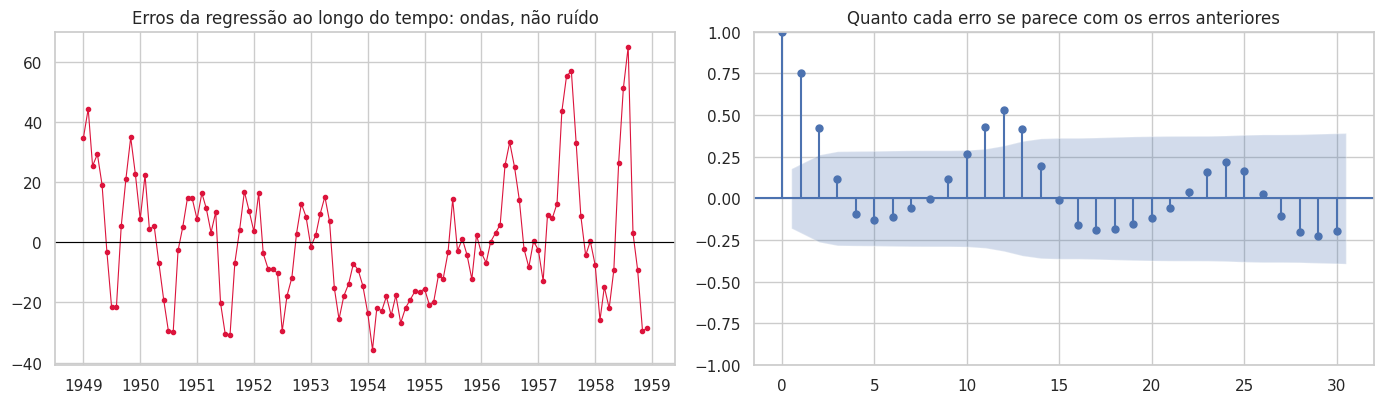

Correlação entre o erro de um mês e o do mês anterior: 0.77
Teste de Ljung-Box (H0: erros sem memória), p-valor = 1.3e-30  -> rejeita com folga


In [ ]:
p_linear = pipeline_calendario(LinearRegression()).fit(X_cal.iloc[:-H], y_cal.iloc[:-H])
residuos_linear = y_cal.iloc[:-H] - p_linear.predict(X_cal.iloc[:-H])

figura, eixos = plt.subplots(1, 2, figsize=(14, 4.2))
eixos[0].plot(residuos_linear, color="crimson", marker="o", markersize=3, linewidth=0.8)
eixos[0].axhline(0, color="black", linewidth=0.8)
eixos[0].set_title("Erros da regressão ao longo do tempo: ondas, não ruído")
plot_acf(residuos_linear, lags=30, ax=eixos[1], title="Quanto cada erro se parece com os erros anteriores")
plt.tight_layout()
plt.show()

p_valor = acorr_ljungbox(residuos_linear, lags=[12], return_df=True)["lb_pvalue"].iloc[0]
print(f"Correlação entre o erro de um mês e o do mês anterior: {residuos_linear.autocorr(1):.2f}")
print(f"Teste de Ljung-Box (H0: erros sem memória), p-valor = {p_valor:.1e}  -> rejeita com folga")

> 💡 **Analogia.** Se você subestimou a demanda este mês, é muito provável que tenha subestimado também o mês passado. O erro de hoje **ajuda a prever** o erro de amanhã: o modelo deixou uma **pista** para trás.

> 📌 **Leitura.** Os erros formam **ondas lentas** (grupos de erros positivos seguidos de grupos de erros negativos), e a ACF (o quanto cada erro "lembra" dos anteriores) fica fora da faixa azul em quase todos os lags. Duas consequências: (1) as hipóteses da regressão estão violadas, então erros-padrão e intervalos de confiança ficam **não confiáveis**; (2) existe **informação não aproveitada**. A saída natural é dar ao modelo o **próprio passado da série**, o que fazemos no Módulo 5.

# Módulo 5 — Lags e autocorrelação: dar memória ao modelo

> 🎯 **Objetivo:** entender o que é um lag, o que é autocorrelação, como ler ACF e PACF, e como **transformar uma série em uma tabela de atributos** que qualquer algoritmo de regressão consegue usar.

**No caso:** o Módulo 4 mostrou que o erro de hoje se parece com o de ontem, ou seja, a série tem **memória**. Agora vamos medir essa memória e entregá-la ao modelo.

## 5.1 O que é um lag

Um **lag** é o valor da série **`k` períodos atrás**. O `lag_1` de um mês é o valor do mês anterior; o `lag_12` é o valor do mesmo mês no ano passado.

> 💡 **Analogia.** O lag é o **retrovisor** do carro. Quem dirige olhando só para o painel (o calendário) não sabe de onde veio; quem olha o retrovisor sabe o que acabou de acontecer e consegue antecipar a próxima curva.

Na prática, criar um lag é **deslocar a série para baixo**: a linha de março passa a ter ao lado o valor de fevereiro.

In [ ]:
amostra = serie.iloc[:8]
tabela_exemplo = pd.DataFrame({
    "y (valor do mês)": amostra,
    "lag_1 (mês anterior)": amostra.shift(1),
    "lag_2 (2 meses antes)": amostra.shift(2),
    "lag_3 (3 meses antes)": amostra.shift(3),
})
tabela_exemplo

,y (valor do mês),lag_1 (mês anterior),lag_2 (2 meses antes),lag_3 (3 meses antes)
1949-01-01,112,NaN,NaN,NaN
1949-02-01,118,112.0,NaN,NaN
1949-03-01,132,118.0,112.0,NaN
1949-04-01,129,132.0,118.0,112.0
1949-05-01,121,129.0,132.0,118.0
1949-06-01,135,121.0,129.0,132.0
1949-07-01,148,135.0,121.0,129.0
1949-08-01,148,148.0,135.0,121.0


> 📌 **Leitura.** Olhe a linha de abril de 1949: `y = 129`, `lag_1 = 132` (março), `lag_2 = 118` (fevereiro), `lag_3 = 112` (janeiro). Cada coluna de lag é a mesma série, só **deslocada**. As primeiras linhas ficam com `NaN` porque ainda não existe passado suficiente: **cada lag usado custa uma linha de treino**.

## 5.2 O que é autocorrelação

Se o valor de hoje se parece com o valor de `k` meses atrás, dizemos que a série tem **autocorrelação no lag `k`**. É a correlação comum, só que da série **com ela mesma deslocada**. O gráfico abaixo mostra isso para três lags.

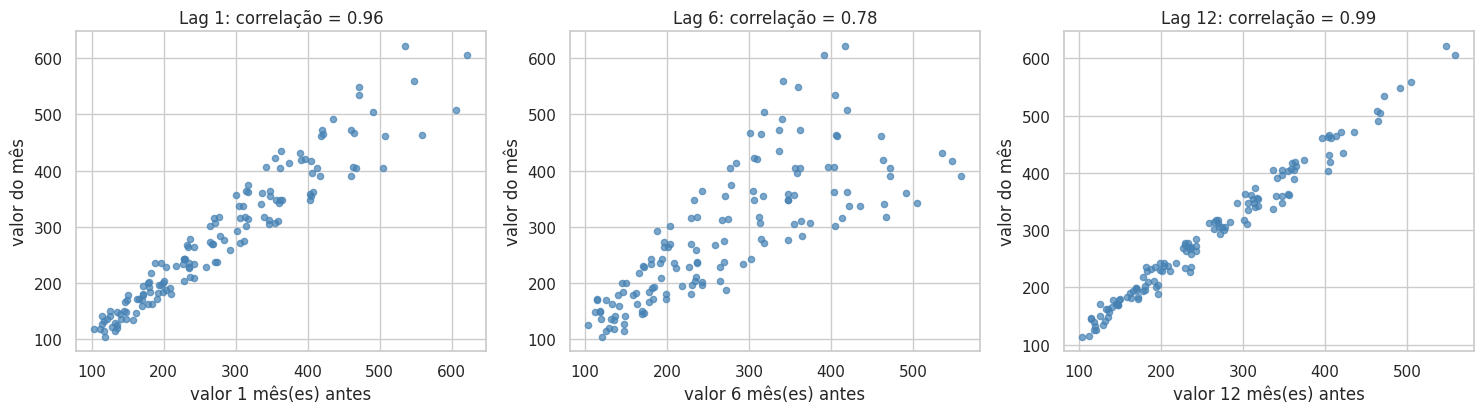

In [ ]:
figura, eixos = plt.subplots(1, 3, figsize=(15, 4.3))
for eixo, lag in zip(eixos, [1, 6, 12]):
    eixo.scatter(serie.shift(lag), serie, color="steelblue", s=20, alpha=0.7)
    eixo.set_xlabel(f"valor {lag} mês(es) antes"); eixo.set_ylabel("valor do mês")
    eixo.set_title(f"Lag {lag}: correlação = {serie.autocorr(lag=lag):.2f}")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** Nos lags 1 e 12, os pontos formam uma nuvem bem alinhada (correlação altíssima): o mês de hoje se parece muito com o mês passado **e** com o mesmo mês do ano passado. No lag 6, a nuvem é mais solta: seis meses separam um pico de um vale. **Quanto mais alinhada a nuvem, mais útil aquele lag é como atributo.**

## 5.3 ACF e PACF: o resumo de todos os lags

Em vez de olhar um lag por vez, a **ACF** (função de autocorrelação) mostra a autocorrelação de **todos os lags de uma vez**. A **PACF** (autocorrelação parcial) mostra a influência **direta** de cada lag, descontando os intermediários.

> 💡 **Analogia.** Imagine uma notícia que passou de pessoa em pessoa. A **ACF** mede quanto da notícia chegou até você, **inclusive pelos intermediários**. A **PACF** mede quanto você ouviu **diretamente** de cada pessoa, sem contar o que veio repassado por outras.

As barras que saem da **faixa azul** são estatisticamente diferentes de zero (memória real).

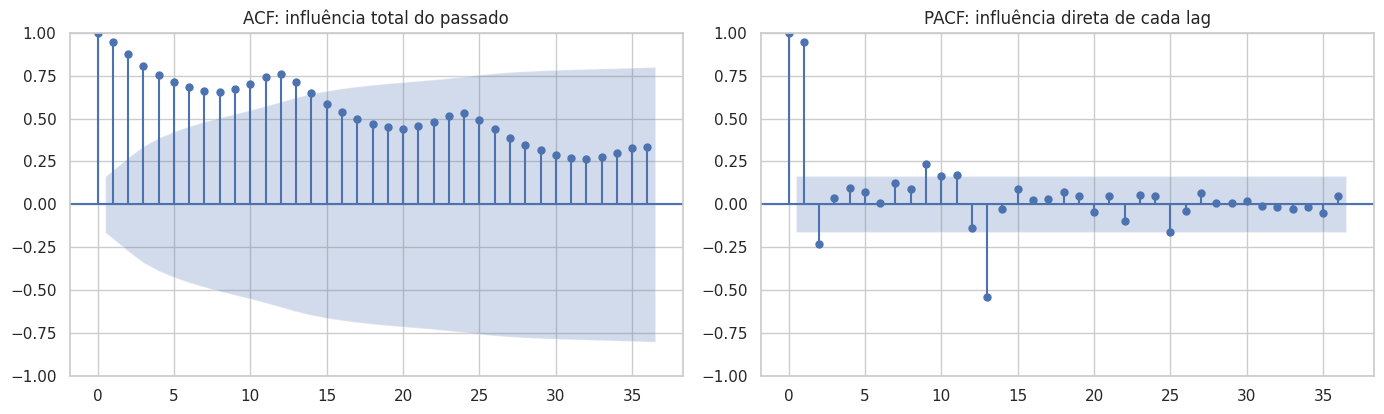

In [ ]:
figura, eixos = plt.subplots(1, 2, figsize=(14, 4.3))
plot_acf(serie, lags=36, ax=eixos[0], title="ACF: influência total do passado")
plot_pacf(serie, lags=36, ax=eixos[1], method="ywm", title="PACF: influência direta de cada lag")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** A **ACF** decai bem devagar e permanece alta por vários anos: é o retrato de uma série com tendência (o nível "lembra" de si mesmo por muito tempo), com uma pequena elevação perto do lag 12 (a sazonalidade). A **PACF** tem um efeito direto enorme no **lag 1** e outro marcante em torno do **lag 12 e 13** (o mesmo mês do ano passado), com o resto pequeno.

**Como escolher os lags para a tabela?** Uma regra prática: os **recentes** (1, 2, 3, que carregam o "momento" da série) mais o **lag sazonal** (12, o mesmo mês do ano anterior). Escolhemos `(1, 2, 3, 12)`. Não é uma lei: é um ponto de partida, e o ideal é testar variações (faremos no Exercício 2). Quanto mais lags, mais atributos e **menos linhas** de treino.


In [ ]:
LAGS = (1, 2, 3, 12)


def montar_atributos(s, lags=LAGS):
    """Transforma uma serie em tabela supervisionada: alvo = valor do mes; atributos = lags + mes do calendario."""
    tabela = pd.DataFrame({"y": s})
    for lag in lags:
        tabela[f"lag_{lag}"] = s.shift(lag)        # desloca a serie para baixo: o passado fica ao lado do presente
    tabela["mes"] = s.index.month                   # calendario: ajuda o modelo a reconhecer a sazonalidade
    return tabela.dropna()                          # as primeiras linhas nao tem passado suficiente


def colunas_atributos(lags=LAGS):
    return [f"lag_{lag}" for lag in lags] + ["mes"]


tabela_lags = montar_atributos(serie)
print(f"A série tinha {len(serie)} meses; a tabela tem {len(tabela_lags)} linhas (perdemos {len(serie) - len(tabela_lags)} por causa do lag 12).")
print(f"Atributos X: {colunas_atributos()} | alvo y: valor do mês")
tabela_lags.head(4)

A série tinha 144 meses; a tabela tem 132 linhas (perdemos 12 por causa do lag 12).
Atributos X: ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'mes'] | alvo y: valor do mês


,y,lag_1,lag_2,lag_3,lag_12,mes
1950-01-01,115,118.0,104.0,119.0,112.0,1
1950-02-01,126,115.0,118.0,104.0,118.0,2
1950-03-01,141,126.0,115.0,118.0,132.0,3
1950-04-01,135,141.0,126.0,115.0,129.0,4


> 📌 **Leitura.** Na linha de janeiro de 1950, `y = 115`, e os atributos são: dezembro/49 (`lag_1 = 118`), novembro/49 (`lag_2 = 104`), outubro/49 (`lag_3 = 119`), janeiro/49 (`lag_12 = 112`) e `mes = 1`. A partir daqui, **qualquer algoritmo de regressão** do scikit-learn pode ser treinado nesta tabela.

## 5.5 Dois significados de "janela"

A palavra **janela** aparece em duas ideias diferentes, e vale separá-las desde já:

| Janela | Pergunta que responde | Neste caso |
|---|---|---|
| **Janela de atributos** (*lookback*) | Até quantos meses para trás o modelo olha para **cada previsão**? | Até 12 meses (o maior lag) |
| **Janela de treino** | Quanto do **histórico** usamos para **treinar** o modelo? | Todo o histórico, ou só os últimos N meses (decidimos no Módulo 10) |

## 5.6 Armadilha: o vazamento ao construir atributos

Um atributo muito comum é a **média móvel dos últimos 3 meses**. O erro clássico é calculá-la **incluindo o mês atual**, o que entrega a resposta ao modelo.

In [ ]:
log_serie = np.log(serie)


def tabela_com_media_movel(s, vazando):
    tabela = montar_atributos(s)
    # ERRADO: rolling(3) inclui o proprio valor de hoje.   CERTO: shift(1) antes, so usa o passado.
    tabela["media_movel_3"] = (s.rolling(3).mean() if vazando else s.shift(1).rolling(3).mean()).reindex(tabela.index)
    return tabela.dropna()


linhas_vazamento = []
for vazando in (True, False):
    t = tabela_com_media_movel(log_serie, vazando)
    colunas = [c for c in t.columns if c != "y"]
    tr, te = t.iloc[:-H], t.iloc[-H:]
    prep = ColumnTransformer([("mes", OneHotEncoder(handle_unknown="ignore"), ["mes"])], remainder="passthrough")
    p = Pipeline([("prep", prep), ("modelo", LinearRegression())]).fit(tr[colunas], tr["y"])
    mae = mean_absolute_error(np.exp(te["y"]), np.exp(p.predict(te[colunas])))
    linhas_vazamento.append({"versão": "ERRADO: rolling(3) sem deslocar" if vazando else "CERTO: shift(1).rolling(3)", "erro médio no teste (milhares)": mae})

pd.DataFrame(linhas_vazamento).set_index("versão").round(3)

,erro médio no teste (milhares)
versão,
ERRADO: rolling(3) sem deslocar,0.000
CERTO: shift(1).rolling(3),14.575


> 💡 **Analogia.** É **colar na prova**: a "média dos últimos 3 meses incluindo hoje" já contém o valor de hoje, e o modelo só desfaz a conta. O erro quase zero não é inteligência, é cola.

> 🚩 **Armadilha.** A versão com vazamento tem erro **praticamente zero**. Um resultado quase perfeito em previsão de série temporal deve **sempre** levantar suspeita. Regra de ouro: **todo atributo só pode usar informação disponível *antes* do instante que se quer prever.** Na prática: `shift` antes de `rolling`, e nunca `center=True`.

## Resumo do módulo

| Conceito | Em uma frase |
|---|---|
| Lag | O valor da série `k` períodos atrás (o retrovisor) |
| Autocorrelação | O quanto a série se parece com ela mesma deslocada |
| ACF | Autocorrelação de todos os lags, incluindo o efeito indireto |
| PACF | Efeito direto de cada lag, descontando os intermediários |
| Tabela de lags | Cada linha = alvo + o recorte do passado que o modelo enxerga |
| Janela de atributos x de treino | Quanto olho para trás por previsão x quanto histórico uso para treinar |
| Vazamento | Atributo que usa o presente ou o futuro. Sempre `shift` antes de `rolling` |

# Módulo 6 — Algoritmos clássicos de regressão sobre os lags

> 🎯 **Objetivo:** treinar SVR, Random Forest e Gradient Boosting na tabela de lags e descobrir o que acontece quando pedimos previsões de vários meses à frente.

**No caso:** temos a tabela. Qualquer algoritmo de regressão serve de "motor". Vamos comparar três clássicos, **todos recebendo exatamente a mesma tabela**.

> 💡 **Analogia.** É o mesmo conjunto de pistas entregue a três detetives com métodos diferentes. A tabela (as pistas) é a mesma; o que muda é como cada um raciocina.

## 6.1 Os três algoritmos

**SVR (*Support Vector Regression*)**
- **Intuição:** traça uma **faixa** (um "tubo") em volta de uma curva suave e só se incomoda com os pontos que ficam **fora** da faixa.
- **Como treina (`fit`):** ajusta uma função não linear (kernel RBF) tolerando erros dentro do tubo. `C` controla o rigor com os pontos fora do tubo, `epsilon` é a largura do tubo e `gamma` é o quão "local" é a curva. **Precisa de variáveis padronizadas.**
- **Como infere (`predict`):** calcula a posição do novo ponto em relação aos pontos de treino mais parecidos com ele.
- **Quando usar:** poucos dados e relação suave e não linear. Sensível aos hiperparâmetros e lento em bases grandes.

**Random Forest**
- **Intuição:** uma **votação** de centenas de árvores de decisão, cada uma treinada em uma amostra diferente dos dados.
- **Como treina:** cada árvore é treinada em uma amostra aleatória das linhas e dos atributos, e aprende regras do tipo "se `lag_12` for maior que X, então...".
- **Como infere:** a previsão é a **média** das previsões das árvores.
- **Quando usar:** relações não lineares e interações, com pouco ajuste. Robusto, mas **não extrapola** valores fora do que viu no treino.

**Gradient Boosting**
- **Intuição:** uma **equipe em fila**, em que cada nova árvore tenta **corrigir os erros** das anteriores.
- **Como treina:** árvores pequenas, uma após a outra, cada uma ajustada ao que ainda está errado.
- **Como infere:** soma as contribuições de todas as árvores.
- **Quando usar:** costuma ser o mais preciso em dados tabulares, com mais cuidado para não sobreajustar. Também **não extrapola**.

Como **referência**, mantemos também o **Ridge** (regressão linear com regularização), que já usamos antes: ele é o contraste útil, porque uma reta **continua subindo** no futuro.

## 6.2 Escolhendo os hiperparâmetros do SVR com validação temporal

O SVR é o mais sensível a `C`, `epsilon` e `gamma`. Escolhemos por busca em grade, mas com `TimeSeriesSplit` (e não com validação cruzada embaralhada), usando **apenas o treino**.

In [ ]:
def construir_pipeline(modelo, lags=LAGS):
    """One-hot no mes e padronizacao dos lags (indispensavel para SVR; ajuda o Ridge)."""
    prep = ColumnTransformer([
        ("mes", OneHotEncoder(handle_unknown="ignore"), ["mes"]),
        ("lags", StandardScaler(), [f"lag_{lag}" for lag in lags]),
    ])
    return Pipeline([("prep", prep), ("modelo", modelo)])


tabela_treino_lags = montar_atributos(np.log(treino))   # a busca so enxerga o TREINO

busca_svr = GridSearchCV(
    construir_pipeline(SVR()),
    param_grid={"modelo__C": [1, 10, 100], "modelo__epsilon": [0.001, 0.01], "modelo__gamma": [0.01, 0.1, "scale"]},
    cv=TimeSeriesSplit(n_splits=5, test_size=12),
    scoring="neg_mean_absolute_error",
).fit(tabela_treino_lags[colunas_atributos()], tabela_treino_lags["y"])

melhores_svr = {k.replace("modelo__", ""): v for k, v in busca_svr.best_params_.items()}
print("Melhores hiperparâmetros do SVR (validação temporal, só no treino):", melhores_svr)

Melhores hiperparâmetros do SVR (validação temporal, só no treino): {'C': 10, 'epsilon': 0.01, 'gamma': 0.01}


## 6.3 Treinando os quatro e prevendo 24 meses

Aqui aparece a diferença mais importante em relação à regressão comum. Existem duas formas de avaliar:

- **Um passo à frente:** para cada mês de teste, usa os lags **reais**. Responde "se eu soubesse tudo até ontem, quão bem preveria hoje?". É a pergunta **fácil**.
- **Previsão recursiva (24 passos):** prevê o mês 1, **usa essa previsão como lag** para prever o mês 2, e assim por diante. É o que acontece quando olhamos 24 meses adiante.

> 💡 **Analogia.** A previsão recursiva é um **telefone sem fio**: cada previsão alimenta a seguinte, e o erro de uma passa para a próxima, acumulando.

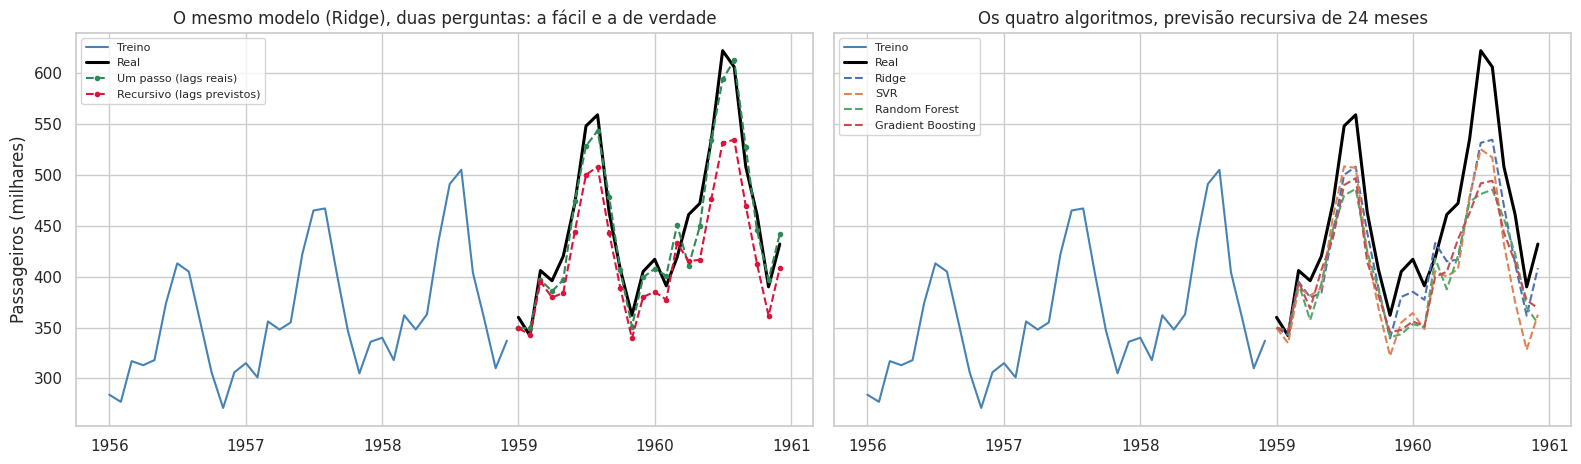

,erro % um passo à frente (fácil),"erro % recursivo, 24 passos (de verdade)"
modelo,,
Ridge,3.14,6.99
SVR,4.41,10.03
Random Forest,7.25,9.87
Gradient Boosting,7.31,9.34


In [ ]:
def prever_um_passo(modelo, serie_completa, h):
    """Usa os lags REAIS do periodo de teste (nao e' previsao de verdade para h > 1)."""
    tabela = montar_atributos(np.log(serie_completa))
    tr, te = tabela.iloc[:-h], tabela.iloc[-h:]
    pipeline = construir_pipeline(clone(modelo)).fit(tr[colunas_atributos()], tr["y"])
    return pd.Series(np.exp(pipeline.predict(te[colunas_atributos()])), index=te.index)


def prever_com_regressao(serie_treino, h, modelo, com_tendencia=False):
    """Treina e preve h meses de forma RECURSIVA. Se com_tendencia=True, remove uma reta de tendencia do log
    antes de modelar o que sobra e a soma de volta no final (veja o Modulo 7)."""
    log_s = np.log(serie_treino)
    n = len(log_s)
    if com_tendencia:
        coef = np.polyfit(np.arange(n), log_s.values, 1)
        alvo_serie = log_s - pd.Series(np.polyval(coef, np.arange(n)), index=log_s.index)
    else:
        alvo_serie = log_s
    tabela = montar_atributos(alvo_serie)
    pipeline = construir_pipeline(clone(modelo)).fit(tabela[colunas_atributos()], tabela["y"])

    historia = list(alvo_serie.values)
    datas = pd.date_range(serie_treino.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    previsoes_log = []
    for i, data in enumerate(datas):
        linha = {f"lag_{lag}": historia[-lag] for lag in LAGS}   # usa as PROPRIAS previsoes anteriores
        linha["mes"] = data.month
        y_hat = pipeline.predict(pd.DataFrame([linha])[colunas_atributos()])[0]
        historia.append(y_hat)
        previsoes_log.append(y_hat + (np.polyval(coef, n + i) if com_tendencia else 0.0))
    return pd.Series(np.exp(previsoes_log), index=datas)


modelos_regressao = {
    "Ridge": Ridge(alpha=0.1),                                                    # referencia linear
    "SVR": SVR(**melhores_svr),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEMENTE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEMENTE),
}

linhas_passos, prev_um_passo, prev_recursiva = [], {}, {}
for nome, modelo in modelos_regressao.items():
    prev_um_passo[nome] = prever_um_passo(modelo, serie, H)
    prev_recursiva[nome] = prever_com_regressao(treino, H, modelo)
    registrar(f"{nome} (lags, recursivo)", prev_recursiva[nome])
    linhas_passos.append({
        "modelo": nome,
        "erro % um passo à frente (fácil)": metricas(teste, prev_um_passo[nome])["MAPE (%)"],
        "erro % recursivo, 24 passos (de verdade)": metricas(teste, prev_recursiva[nome])["MAPE (%)"],
    })

figura, eixos = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
eixos[0].plot(treino.iloc[-36:], color="steelblue", label="Treino"); eixos[0].plot(teste, color="black", linewidth=2.2, label="Real")
eixos[0].plot(prev_um_passo["Ridge"], color="seagreen", linestyle="--", marker="o", markersize=3, label="Um passo (lags reais)")
eixos[0].plot(prev_recursiva["Ridge"], color="crimson", linestyle="--", marker="o", markersize=3, label="Recursivo (lags previstos)")
eixos[0].set_title("O mesmo modelo (Ridge), duas perguntas: a fácil e a de verdade"); eixos[0].legend(fontsize=8, loc="upper left")
eixos[1].plot(treino.iloc[-36:], color="steelblue", label="Treino"); eixos[1].plot(teste, color="black", linewidth=2.2, label="Real")
for nome, prev in prev_recursiva.items():
    eixos[1].plot(prev, linestyle="--", label=nome)
eixos[1].set_title("Os quatro algoritmos, previsão recursiva de 24 meses"); eixos[1].legend(fontsize=8, loc="upper left")
eixos[0].set_ylabel("Passageiros (milhares)")
plt.tight_layout()
plt.show()

pd.DataFrame(linhas_passos).set_index("modelo").round(2)

> 📌 **Leitura.** À esquerda: a linha verde (um passo) cola na série real; a vermelha (recursiva) vai se afastando, porque cada previsão carrega o erro da anterior. Na tabela, o erro de um passo à frente é **menor nos quatro modelos**. **Reportar só o erro de um passo à frente para um problema de 24 meses é uma forma sutil de se enganar.**

À direita: todos acertam o **formato** do ciclo anual (a tabela de lags fez seu trabalho), mas os picos de 1960 ficam **subestimados**, e **Random Forest e Gradient Boosting ficam ainda mais abaixo do Ridge**, enquanto o SVR acompanha o formato mas escorrega nos vales de 1960. O motivo é o assunto do próximo módulo.

# Módulo 7 — O problema da tendência: o que árvores e SVR não fazem

> 🎯 **Objetivo:** entender por que Random Forest, Gradient Boosting e SVR falham em séries com tendência, e como corrigir.

**No caso:** a série cresce todos os anos, então os valores futuros são **maiores que qualquer valor do treino**. É uma situação que a regressão comum raramente enfrenta.

> 💡 **Analogia.** Esses três algoritmos são como um estagiário que só consulta o **histórico**: respondem com o que já viram. Se a pergunta é sobre um número maior que todos os do arquivo, devolvem o maior que conhecem. O Ridge, por ser uma reta, **continua a reta**.

**A correção:** em vez de pedir que o modelo preveja a série inteira, **tiramos a tendência primeiro**. Ajustamos uma reta ao log da série, deixamos o modelo aprender só o que **sobra** (que oscila em uma faixa fixa, dentro do que ele já viu) e **somamos a reta de volta** no final. É um modelo **híbrido**: a tendência é linear, o resto é flexível.

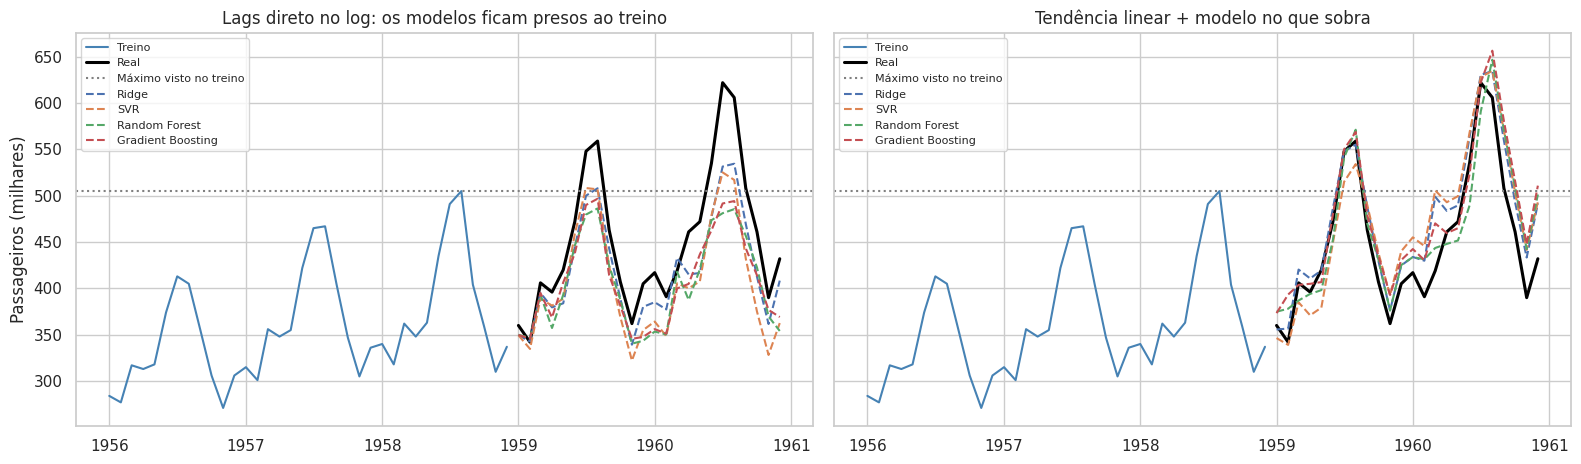

,erro % sem remover a tendência,erro % removendo a tendência
modelo,,
Ridge,6.99,5.48
SVR,10.03,7.88
Random Forest,9.87,6.20
Gradient Boosting,9.34,6.40


In [ ]:
max_treino = treino.max()

linhas_tendencia, prev_hibrida = [], {}
for nome, modelo in modelos_regressao.items():
    prev_hibrida[nome] = prever_com_regressao(treino, H, modelo, com_tendencia=True)
    registrar(f"{nome} (tendência + resíduo, recursivo)", prev_hibrida[nome])
    linhas_tendencia.append({
        "modelo": nome,
        "erro % sem remover a tendência": metricas(teste, prev_recursiva[nome])["MAPE (%)"],
        "erro % removendo a tendência": metricas(teste, prev_hibrida[nome])["MAPE (%)"],
    })

figura, eixos = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for eixo, prevs, titulo in [(eixos[0], prev_recursiva, "Lags direto no log: os modelos ficam presos ao treino"),
                            (eixos[1], prev_hibrida, "Tendência linear + modelo no que sobra")]:
    eixo.plot(treino.iloc[-36:], color="steelblue", label="Treino")
    eixo.plot(teste, color="black", linewidth=2.2, label="Real")
    eixo.axhline(max_treino, color="gray", linestyle=":", label="Máximo visto no treino")
    for nome in modelos_regressao:
        eixo.plot(prevs[nome], linestyle="--", label=nome)
    eixo.set_title(titulo); eixo.legend(fontsize=8, loc="upper left")
eixos[0].set_ylabel("Passageiros (milhares)")
plt.tight_layout()
plt.show()

pd.DataFrame(linhas_tendencia).set_index("modelo").round(2)

> 📌 **Leitura.** À esquerda, os picos de 1960 mal chegam ao máximo histórico (linha pontilhada), embora o real passe muito dele. À direita, com a tendência removida, as previsões **seguem o crescimento**, e o erro de SVR, Random Forest e Gradient Boosting cai de forma clara (de cerca de 9 a 10% para 6 a 8%). O Ridge também melhora, porém menos: ele já extrapolava.

> 🚩 **Armadilha.** **Modelos baseados em árvore ou em kernel (SVR) em séries com tendência** pedem que o problema seja tornado estacionário antes (tirando uma tendência, ou trabalhando com diferenças ou razões). Isso não existe na regressão tabular comum, porque lá os dados novos costumam cair dentro da faixa vista no treino.

# Módulo 8 — O especialista: SARIMA e Holt-Winters, em resumo

> 🎯 **Objetivo:** conhecer, sem se aprofundar, os modelos feitos **especificamente** para séries temporais, e ver como eles se comparam com o que já construímos.

**No caso:** o diretor pergunta se não existe uma ferramenta feita para isso. Existe, e usa a mesma ideia dos lags, com a "contabilidade" da tendência e da sazonalidade embutida no próprio modelo.

## 8.1 A família ARMA, ARIMA e SARIMA em uma tabela

> 💡 **Analogia.** Todos só sabem andar em **terreno plano**, ou seja, em séries sem tendência (ladeira) nem sazonalidade (gangorra). Antes de modelar, é preciso "aplainar" a série. Quando isso é feito, dizemos que ela é **estacionária**.

| Modelo | Ideia em uma frase | Quando usar |
|---|---|---|
| **AR** (autorregressivo) | O valor de hoje é um **eco dos valores recentes** (parente próximo da regressão com lags) | Série já aplainada |
| **MA** (média móvel) | O valor de hoje é um **eco das surpresas recentes** (os erros de previsão dos últimos meses) | Série já aplainada |
| **ARMA** | Os dois ecos juntos | Série já aplainada |
| **ARIMA** | Um ARMA com a **diferença simples embutida** (ele aplaina a tendência sozinho). O "I" é de *integrated* | Série com tendência |
| **SARIMA** | Um ARIMA com uma **segunda camada que olha de 12 em 12 meses**, para a sazonalidade | Tendência e sazonalidade estáveis |

As "ferramentas de aplainar" são: o **log** (estabiliza a oscilação), a **diferença simples**, `d=1` (em vez do valor, olhar a variação em relação ao mês anterior) e a **diferença sazonal**, `D=1` (em vez do valor, olhar a variação em relação ao mesmo mês do ano passado). O **teste ADF** diz se funcionou: p-valor menor que 0,05 indica série estacionária.

ADF da série original : p = 0.992 -> NÃO estacionária (ladeira + gangorra)
ADF após log, d=1, D=1: p = 0.0002 -> estacionária (terreno plano)


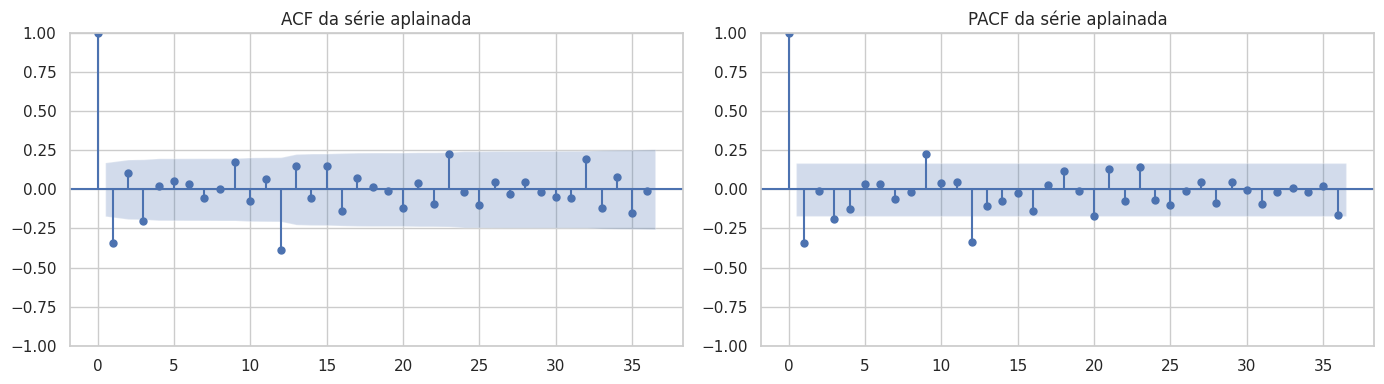

In [ ]:
serie_estacionaria = np.log(serie).diff().diff(12).dropna()   # log, d=1 e D=1

p_original = adfuller(serie, autolag="AIC")[1]
p_aplainada = adfuller(serie_estacionaria, autolag="AIC")[1]
print(f"ADF da série original : p = {p_original:.3f} -> NÃO estacionária (ladeira + gangorra)")
print(f"ADF após log, d=1, D=1: p = {p_aplainada:.4f} -> estacionária (terreno plano)")

figura, eixos = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(serie_estacionaria, lags=36, ax=eixos[0], title="ACF da série aplainada")
plot_pacf(serie_estacionaria, lags=36, ax=eixos[1], method="ywm", title="PACF da série aplainada")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** Depois de aplainar, sobra **pouca memória**: quase todas as barras cabem na faixa azul, restando dois picos negativos, no **lag 1** (o mês anterior) e no **lag 12** (o mesmo mês do ano passado). Esse retrato sugere um termo de **média móvel** na parte mensal e outro na parte sazonal, o que é escrito como **SARIMA(0,1,1)(0,1,1)₁₂**, o famoso "modelo das companhias aéreas" de Box e Jenkins. Repare que a ACF/PACF do Módulo 5 foi a **mesma ferramenta**, aplicada agora para escolher a ordem do modelo.

## 8.2 Ajustando SARIMA e Holt-Winters

A **suavização exponencial (Holt-Winters)** é uma alternativa sem ARIMA: a previsão é uma **média ponderada do passado em que os meses recentes pesam mais**. Ela mantém três "contadores" atualizados (nível, tendência e padrão sazonal). Comparamos com o ARIMA sem sazonalidade, para ver o que a camada sazonal acrescenta.

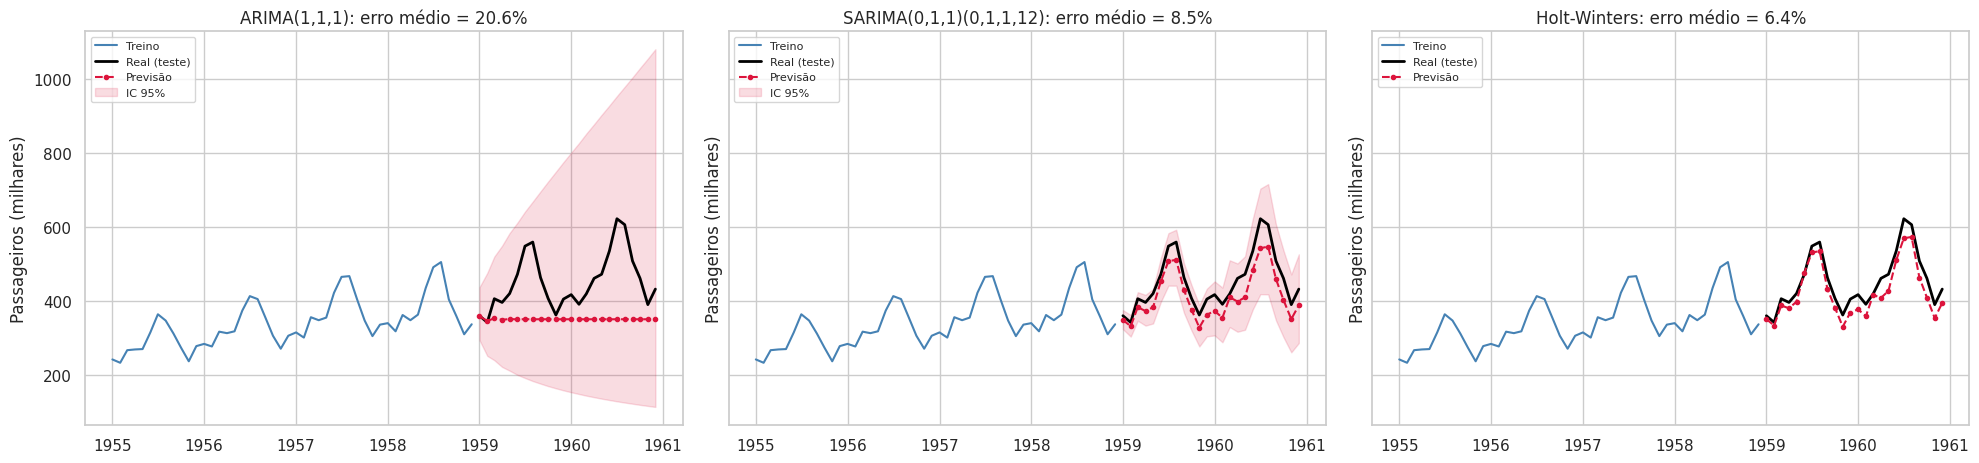

Resíduos do SARIMA: Ljung-Box (H0: sem memória), p = 0.80 -> não rejeita: sobrou só ruído, como queremos


In [ ]:
log_treino = np.log(treino)
modelo_arima = ARIMA(log_treino, order=(1, 1, 1)).fit()
modelo_sarima = SARIMAX(log_treino, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
modelo_hw = ExponentialSmoothing(treino, trend="add", seasonal="mul", seasonal_periods=12).fit()

figura, eixos = plt.subplots(1, 3, figsize=(20, 4.8), sharey=True)
for eixo, nome, modelo in [(eixos[0], "ARIMA(1,1,1)", modelo_arima), (eixos[1], "SARIMA(0,1,1)(0,1,1,12)", modelo_sarima)]:
    previsao_log = modelo.get_forecast(H)
    prev = np.exp(previsao_log.predicted_mean)
    intervalo = np.exp(previsao_log.conf_int(alpha=0.05))
    m = registrar(nome, prev)
    plotar_previsao(f"{nome}: erro médio = {m['MAPE (%)']:.1f}%", prev, intervalo, eixo=eixo)

prev_hw = modelo_hw.forecast(H)
m = registrar("Holt-Winters (tendência aditiva, sazonal multiplicativa)", prev_hw)
plotar_previsao(f"Holt-Winters: erro médio = {m['MAPE (%)']:.1f}%", prev_hw, eixo=eixos[2])
plt.tight_layout()
plt.show()

residuos_sarima = modelo_sarima.resid.iloc[13:]
p_ljung = acorr_ljungbox(residuos_sarima, lags=[24], return_df=True)["lb_pvalue"].iloc[0]
print(f"Resíduos do SARIMA: Ljung-Box (H0: sem memória), p = {p_ljung:.2f} -> não rejeita: sobrou só ruído, como queremos")

> 📌 **Leitura.** O **ARIMA** devolve uma linha praticamente horizontal: sem componente sazonal não há ciclo anual, e sem deriva ele projeta o último nível (erro alto, pior que o naive sazonal). O **SARIMA** reproduz o ciclo anual, com um **intervalo de confiança** que se abre com o horizonte, algo que as regressões não entregam de graça. O **Holt-Winters** chega a um resultado na mesma faixa sem nenhum teste de estacionariedade. E o teste de Ljung-Box confirma o que o Módulo 4 pedia: **depois do SARIMA, os resíduos não têm mais memória**, ou seja, a informação do passado foi aproveitada.

# Módulo 9 — Placar final e a diferença entre regressão e série temporal

> 🎯 **Objetivo:** colocar todos os modelos lado a lado e resumir o que muda quando os dados têm ordem no tempo.

## 9.1 O placar

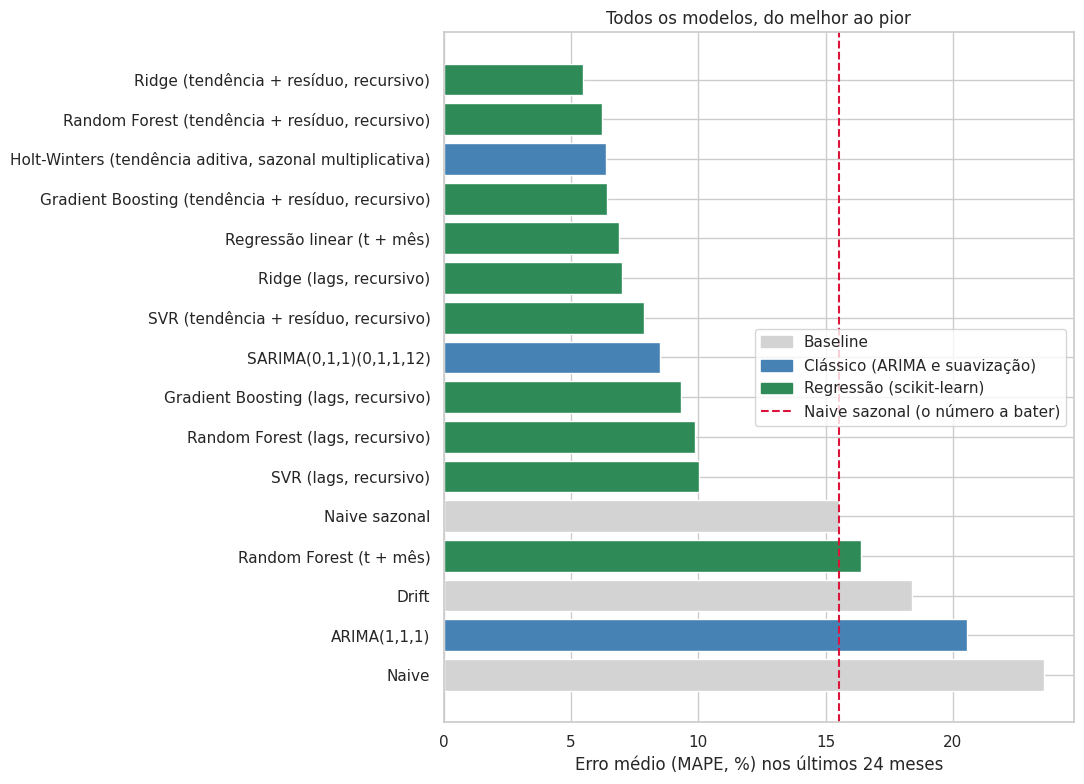

,MAE,RMSE,MAPE (%)
"Ridge (tendência + resíduo, recursivo)",24.03,30.58,5.48
"Random Forest (tendência + resíduo, recursivo)",27.63,32.80,6.20
"Holt-Winters (tendência aditiva, sazonal multiplicativa)",28.98,32.49,6.39
"Gradient Boosting (tendência + resíduo, recursivo)",27.50,36.10,6.40
Regressão linear (t + mês),34.64,47.94,6.88
"Ridge (lags, recursivo)",33.62,39.67,6.99
"SVR (tendência + resíduo, recursivo)",34.69,39.17,7.88
"SARIMA(0,1,1)(0,1,1,12)",39.44,43.18,8.51
"Gradient Boosting (lags, recursivo)",45.10,54.59,9.34
"Random Forest (lags, recursivo)",47.56,58.34,9.87


In [ ]:
tabela_final = pd.DataFrame(resultados).T.sort_values("MAPE (%)")


def familia(nome):
    if nome in ["Naive", "Naive sazonal", "Drift"]:
        return "Baseline"
    if nome.startswith(("ARIMA", "SARIMA", "Holt-Winters")):
        return "Clássico (ARIMA e suavização)"
    return "Regressão (scikit-learn)"


cores_familia = {"Baseline": "lightgray", "Clássico (ARIMA e suavização)": "steelblue", "Regressão (scikit-learn)": "seagreen"}
plt.figure(figsize=(11, 8))
plt.barh(tabela_final.index[::-1], tabela_final["MAPE (%)"].values[::-1], color=[cores_familia[familia(n)] for n in tabela_final.index[::-1]])
plt.axvline(resultados["Naive sazonal"]["MAPE (%)"], color="crimson", linestyle="--")
legenda = [Patch(color=cor, label=nome_familia) for nome_familia, cor in cores_familia.items()]
legenda.append(Line2D([0], [0], color="crimson", linestyle="--", label="Naive sazonal (o número a bater)"))
plt.xlabel("Erro médio (MAPE, %) nos últimos 24 meses"); plt.title("Todos os modelos, do melhor ao pior")
plt.legend(handles=legenda, loc="center right")
plt.tight_layout()
plt.show()

tabela_final.round(2)

> 📌 **Leitura.** O que separa os grupos **não é o algoritmo, é o que ele sabe sobre a série**:
> - **No fim da lista:** baselines sem sazonalidade, o ARIMA e o Random Forest com `t` e mês. Todos **ignoram o ciclo anual ou o crescimento**.
> - **No meio:** as árvores e o SVR com lags "cruas" (sem remover a tendência), que enxergam o ciclo mas sofrem com o crescimento (Módulo 7).
> - **No topo:** modelos que tratam **tendência e sazonalidade**, sejam clássicos (SARIMA, Holt-Winters) ou regressões com a tendência removida antes.
>
> Cuidado com a ordem **dentro** do topo: as diferenças são de poucos pontos percentuais, medidas em **uma única janela de 24 meses**. Nesta janela, o SARIMA ficou atrás dos regressores com tendência removida e do Holt-Winters, e até a regressão linear simples com `t` e mês passou por ele, embora deixe erros com memória (Módulo 4) e não dê intervalo de confiança confiável. A lição prática é escolher pelo conjunto: erro em várias janelas, simplicidade, facilidade de manutenção e se o modelo entrega **intervalo de confiança** (os clássicos entregam; as regressões entregam só um número).

## 9.2 Regressão "normal" x previsão de série temporal

| Aspecto | Regressão "normal" | Previsão de série temporal | Onde vimos |
|---|---|---|---|
| **Pergunta** | Qual o alvo para **este exemplo**? | O que acontece **depois**, dado todo o passado? | M1 |
| **Ordem das linhas** | Não importa | É a informação principal | M1 |
| **Teste** | Linhas sorteadas | Sempre o **final** da série | M3, M4 |
| **Erros** | Supõe-se independentes | Têm **memória** (ondas) e precisam ser checados | M4, M8 |
| **Atributos** | Características do exemplo | Calendário e **valores passados** (lags) | M5 |
| **Vazamento** | Padronizar com o teste, alvo escondido em atributos | Tudo isso, mais o **futuro escondido** em `rolling` sem `shift` | M5 |
| **Previsão de vários passos** | Cada linha de teste é independente | A previsão de hoje vira atributo de amanhã (**telefone sem fio**) | M6 |
| **Tendência** | Quase nunca existe | Leva o futuro **para fora** da faixa vista; **árvores e SVR não extrapolam** | M7 |
| **Janela de treino** | Usa-se tudo que existe | **Quanto do passado** usar é uma decisão (ver Módulo 10) | M10 |
| **Incerteza** | Intervalo por exemplo | Intervalo que **se abre** com o horizonte | M8 |
| **Referência de qualidade** | Comparar com a média | Comparar com o **naive sazonal** | M3, M9 |

**Em uma frase:** uma regressão responde "dado **este** exemplo, qual o alvo?". Uma previsão de série temporal responde "dado **todo o passado**, o que acontece depois?". Quase tudo na tabela decorre dessa mudança de pergunta.

# Módulo 10 — Pipeline de treino e inferência: as janelas

> 🎯 **Objetivo:** juntar tudo em um pipeline simples, com **treino** e **inferência** separados, e entender o papel de cada peça: a **janela de treino**, a **série de entrada** da inferência e a **inferência** em si.

**No caso:** o modelo foi aprovado. Agora o diretor quer usá-lo todo mês. Para isso, precisamos separar claramente duas fases que, até aqui, estavam misturadas na mesma função.

## 10.1 As três peças

> 💡 **Analogia.** Treinar é **estudar para a prova**; a inferência é **fazer a prova**. Na hora da prova, você não relê o caderno inteiro: usa o que aprendeu e o enunciado que recebeu.

| Peça | O que é | Pergunta que responde |
|---|---|---|
| **1. Janela de treino** | O trecho do histórico usado para **ajustar** o modelo (`fit`) | Quanto do passado o modelo estuda? Tudo, ou só os últimos N meses? |
| **2. Série de entrada da inferência** | Os **últimos meses conhecidos** (pelo menos o maior lag, 12), entregues ao modelo na hora de prever | De onde parte a primeira previsão? É o "enunciado" da prova |
| **3. Inferência** | O laço **recursivo**: prevê um mês, usa a previsão como lag, repete até o horizonte | Como chegamos de 12 meses conhecidos a 24 meses previstos? |

O desenho abaixo mostra as três peças na linha do tempo, para as **duas formas de escolher a janela de treino**: a **expansiva** (toda a história até hoje) e a **deslizante** (só os últimos 60 meses, uma janela de tamanho fixo que "anda" com o tempo).

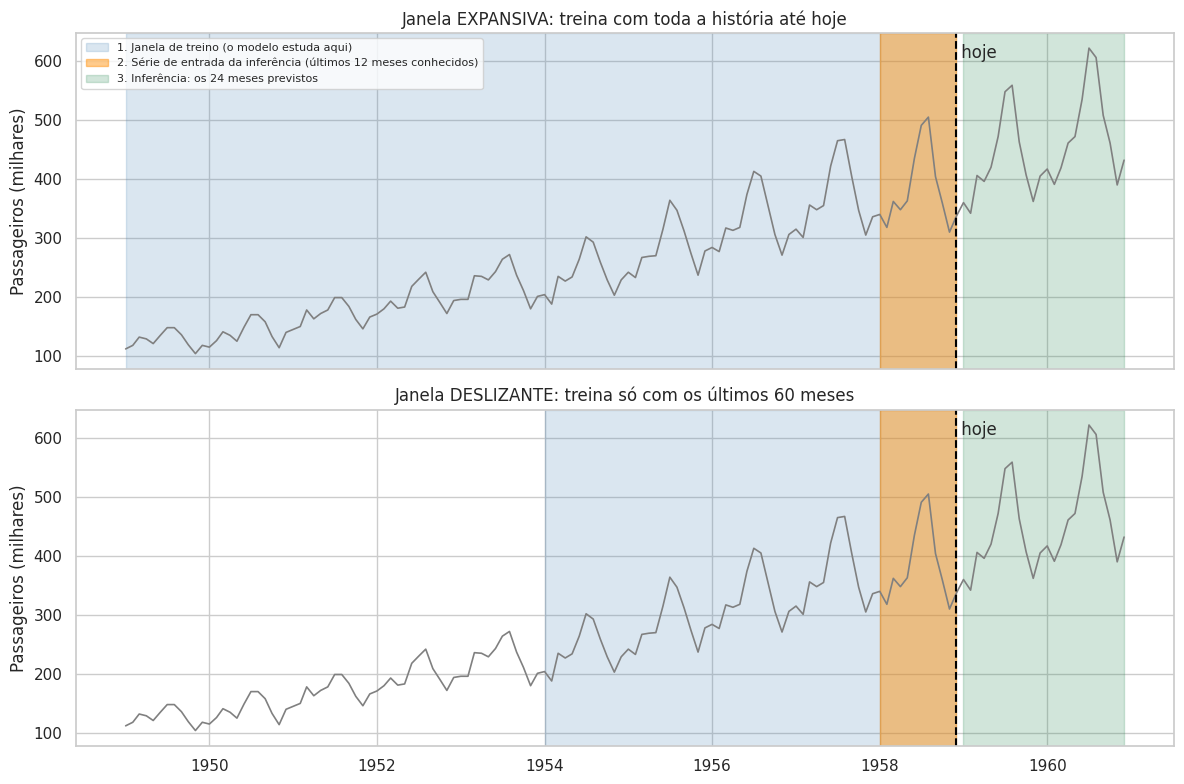

In [ ]:
corte = treino.index[-1]    # "hoje": ultimo mes conhecido (12/1958)
LOOKBACK = max(LAGS)


def desenhar_janelas(eixo, janela_treino, titulo):
    inicio_treino = serie.index[0] if janela_treino is None else corte - pd.DateOffset(months=janela_treino - 1)
    inicio_entrada = corte - pd.DateOffset(months=LOOKBACK - 1)
    eixo.plot(serie.loc[: corte + pd.DateOffset(months=H)], color="gray", linewidth=1.2)
    eixo.axvspan(inicio_treino, corte, color="steelblue", alpha=0.20, label="1. Janela de treino (o modelo estuda aqui)")
    eixo.axvspan(inicio_entrada, corte, color="darkorange", alpha=0.45, label="2. Série de entrada da inferência (últimos 12 meses conhecidos)")
    eixo.axvspan(corte + pd.DateOffset(months=1), corte + pd.DateOffset(months=H), color="seagreen", alpha=0.22, label="3. Inferência: os 24 meses previstos")
    eixo.axvline(corte, color="black", linestyle="--"); eixo.text(corte, eixo.get_ylim()[1] * 0.97, " hoje", va="top")
    eixo.set_title(titulo); eixo.set_ylabel("Passageiros (milhares)")


figura, eixos = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
desenhar_janelas(eixos[0], None, "Janela EXPANSIVA: treina com toda a história até hoje")
desenhar_janelas(eixos[1], 60, "Janela DESLIZANTE: treina só com os últimos 60 meses")
eixos[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

> 📌 **Leitura.** A faixa **laranja** (a série de entrada) é a mesma nas duas versões: os últimos 12 meses conhecidos. O que muda é a faixa **azul**: na expansiva ela cresce a cada mês que passa (o modelo estuda tudo); na deslizante ela tem sempre 60 meses (o modelo "esquece" o passado distante). A faixa **verde** é a saída: o que o modelo entrega.

Note que a faixa laranja fica **dentro** da azul apenas porque estamos simulando "hoje = 12/1958". Em produção, a série de entrada é simplesmente **o dado mais recente que chegou**, e pode ser entregue ao modelo **muito depois** do treino.

## 10.2 O pipeline em código: duas funções e DataFrames

O pipeline não precisa de nada sofisticado: são **duas funções**, e a informação vai passando de uma etapa para a outra em **DataFrames**.

| Função | Recebe | Devolve |
|---|---|---|
| `treinar(serie, modelo, janela_treino)` | a série e o regressor | um **dicionário** com o modelo treinado e tudo de que a inferência vai precisar |
| `prever(modelo_treinado, serie_entrada, h)` | o dicionário, a série de entrada e o horizonte | um **DataFrame** com as previsões |

Cada etapa é uma transformação de tabela: **série → tabela de lags → regressor treinado** (treino), e **série de entrada → tabela que cresce uma linha por mês previsto** (inferência). Estão incorporados o log, a tendência removida (Módulo 7), a tabela de lags (Módulo 5) e a previsão recursiva (Módulo 6). As três peças estão marcadas nos comentários.

In [ ]:
def meses_desde(datas, origem):
    """Quantos meses cada data esta depois de 'origem' (usado pela reta de tendencia)."""
    return (datas.year - origem.year) * 12 + (datas.month - origem.month)


def treinar(serie, modelo, lags=LAGS, janela_treino=None):
    """TREINO: recebe a serie e devolve um dicionario com tudo que a inferencia vai precisar."""
    # PECA 1: JANELA DE TREINO. Toda a serie (expansiva) ou so os ultimos N meses (deslizante).
    janela = serie if janela_treino is None else serie.iloc[-janela_treino:]
    origem = janela.index[0]

    log_janela = np.log(janela)
    meses = meses_desde(log_janela.index, origem)
    coef_tendencia = np.polyfit(meses, log_janela.values, 1)        # reta de tendencia, ajustada so na janela
    residuo = log_janela - np.polyval(coef_tendencia, meses)         # o que sobra depois de tirar a tendencia

    df_treino = montar_atributos(residuo, lags)                      # serie -> tabela de lags (Modulo 5)
    pipeline = construir_pipeline(clone(modelo), lags).fit(df_treino[colunas_atributos(lags)], df_treino["y"])

    return {"pipeline": pipeline, "coef_tendencia": coef_tendencia, "origem": origem, "lags": lags,
            "inicio_janela": janela.index[0], "fim_janela": janela.index[-1], "n_linhas_treino": len(df_treino)}


def prever(modelo_treinado, serie_entrada, h):
    """INFERENCIA: recebe o modelo treinado, a serie de entrada e o horizonte; devolve um DataFrame."""
    lags, coef, origem = modelo_treinado["lags"], modelo_treinado["coef_tendencia"], modelo_treinado["origem"]
    if len(serie_entrada) < max(lags):
        raise ValueError(f"A serie de entrada precisa ter pelo menos {max(lags)} meses.")

    # PECA 2: SERIE DE ENTRADA. Os ultimos meses conhecidos, como uma tabela de uma coluna (sem a tendencia).
    log_entrada = np.log(serie_entrada)
    df = pd.DataFrame({"residuo": log_entrada - np.polyval(coef, meses_desde(log_entrada.index, origem))}).iloc[-max(lags):]

    # PECA 3: INFERENCIA RECURSIVA. A tabela cresce uma linha por mes previsto, e a previsao vira lag do mes seguinte.
    datas = pd.date_range(serie_entrada.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    for data in datas:
        linha = {f"lag_{lag}": df["residuo"].iloc[-lag] for lag in lags}     # os lags saem das ultimas linhas da tabela
        linha["mes"] = data.month
        df.loc[data, "residuo"] = modelo_treinado["pipeline"].predict(pd.DataFrame([linha])[colunas_atributos(lags)])[0]

    df_previsao = df.loc[datas].copy()                                        # so as linhas novas (as previsoes)
    df_previsao["tendencia"] = np.polyval(coef, meses_desde(df_previsao.index, origem))   # soma a tendencia de volta
    df_previsao["previsao"] = np.exp(df_previsao["residuo"] + df_previsao["tendencia"])    # desfaz o log
    return df_previsao


print("Funções treinar() e prever() definidas.")

Funções treinar() e prever() definidas.


## 10.3 Passo a passo, com a janela deslizante

Primeiro uma execução completa, mostrando **exatamente** o que cada peça recebe e devolve. Usamos o Random Forest como modelo (qualquer outro regressor do scikit-learn funciona no lugar).

1. JANELA DE TREINO     : 01/1954 a 12/1958 (60 meses -> 48 linhas na tabela de lags)
2. SERIE DE ENTRADA     : 01/1958 a 12/1958 (12 meses conhecidos)
3. INFERENCIA (SAIDA)   : 01/1959 a 12/1960 (24 meses previstos)

Erro médio contra o que realmente aconteceu: 4.30%

O DataFrame devolvido pela inferência (primeiras linhas):


,residuo,tendencia,previsao
1959-01-01,-0.106,6.044,379.336
1959-02-01,-0.143,6.054,369.171
1959-03-01,-0.074,6.064,399.475
1959-04-01,-0.092,6.074,395.971


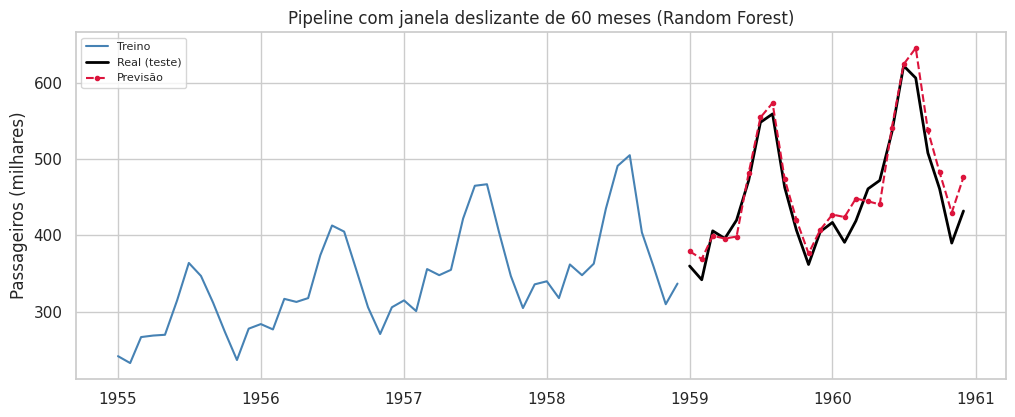

In [ ]:
historico_ate_hoje = serie.loc[:corte]
modelo_exemplo = RandomForestRegressor(n_estimators=300, random_state=SEMENTE)

# PECA 1: treino com a janela deslizante de 60 meses
modelo_treinado = treinar(historico_ate_hoje, modelo_exemplo, janela_treino=60)
print(f"1. JANELA DE TREINO     : {modelo_treinado['inicio_janela']:%m/%Y} a {modelo_treinado['fim_janela']:%m/%Y} "
      f"(60 meses -> {modelo_treinado['n_linhas_treino']} linhas na tabela de lags)")

# PECA 2: a serie de entrada (os ultimos 12 meses conhecidos)
entrada = historico_ate_hoje.iloc[-12:]
print(f"2. SERIE DE ENTRADA     : {entrada.index[0]:%m/%Y} a {entrada.index[-1]:%m/%Y} ({len(entrada)} meses conhecidos)")

# PECA 3: a inferencia, que devolve um DataFrame
df_previsao = prever(modelo_treinado, entrada, h=24)
print(f"3. INFERENCIA (SAIDA)   : {df_previsao.index[0]:%m/%Y} a {df_previsao.index[-1]:%m/%Y} ({len(df_previsao)} meses previstos)")
print(f"\nErro médio contra o que realmente aconteceu: {metricas(teste, df_previsao['previsao'])['MAPE (%)']:.2f}%\n")

print("O DataFrame devolvido pela inferência (primeiras linhas):")
display(df_previsao.head(4).round(3))

plotar_previsao("Pipeline com janela deslizante de 60 meses (Random Forest)", df_previsao["previsao"])

> 📌 **Leitura.** O fluxo é sempre o mesmo, em três linhas: `treinar` com a janela de treino, escolha da série de entrada, `prever`. Observe que o `prever` **não conhece o treino**: ele só recebe o dicionário `modelo_treinado`, a série de entrada e o horizonte. Tudo o que ele precisa do treino (o regressor ajustado e a reta de tendência) está guardado nesse dicionário. É isso que permite treinar **uma vez** e **prever todo mês** com dados novos.

O DataFrame de saída mostra o caminho de cada previsão: `residuo` é o que o regressor previu (em log, sem a tendência), `tendencia` é a reta somada de volta, e `previsao` é o resultado final em milhares de passageiros, depois de desfazer o log.

## 10.4 As duas janelas lado a lado

Agora comparamos as duas formas de escolher a janela de treino, para os quatro algoritmos. Medimos de duas formas: no **holdout** de 24 meses (um único teste) e em **origem móvel** (seis cortes diferentes, cada um prevendo 12 meses), que é uma avaliação bem mais confiável.

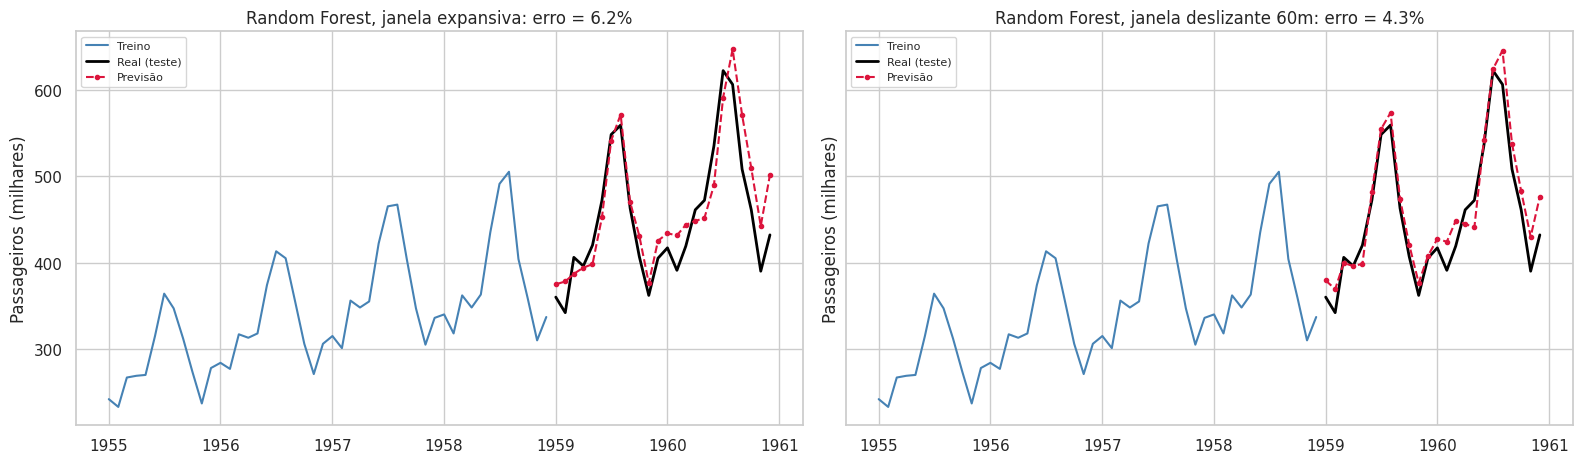

Erro médio (MAPE, %) por modelo e tipo de janela:


,holdout 24m | expansiva,holdout 24m | deslizante 60m,origem móvel | expansiva,origem móvel | deslizante 60m
modelo,,,,
Ridge,5.48,2.62,4.30,3.35
SVR,7.88,7.67,5.01,4.67
Random Forest,6.20,4.30,4.45,3.68
Gradient Boosting,6.40,5.24,4.73,4.19


In [ ]:
def mape_origem_movel(modelo, janela, lags=LAGS, cortes=range(72, 133, 12), h=12):
    """MAPE medio de varios cortes: treina ate cada corte e preve os h meses seguintes."""
    erros = []
    for c in cortes:
        historico, real = serie.iloc[:c], serie.iloc[c:c + h]
        treinado = treinar(historico, modelo, lags=lags, janela_treino=janela)
        previsao = prever(treinado, historico.iloc[-max(lags):], h=len(real))["previsao"]
        erros.append(metricas(real, previsao)["MAPE (%)"])
    return np.mean(erros)


janelas = {"expansiva": None, "deslizante 60m": 60}
linhas_janelas, prevs_rf = [], {}
for nome, modelo in modelos_regressao.items():
    linha = {"modelo": nome}
    for nome_janela, tamanho in janelas.items():
        treinado = treinar(historico_ate_hoje, modelo, janela_treino=tamanho)
        prev = prever(treinado, historico_ate_hoje.iloc[-12:], h=H)["previsao"]
        linha[f"holdout 24m | {nome_janela}"] = metricas(teste, prev)["MAPE (%)"]
        if nome == "Random Forest":
            prevs_rf[nome_janela] = prev
    for nome_janela, tamanho in janelas.items():
        linha[f"origem móvel | {nome_janela}"] = mape_origem_movel(modelo, tamanho)
    linhas_janelas.append(linha)

figura, eixos = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for eixo, (nome_janela, prev) in zip(eixos, prevs_rf.items()):
    plotar_previsao(f"Random Forest, janela {nome_janela}: erro = {metricas(teste, prev)['MAPE (%)']:.1f}%", prev, eixo=eixo)
plt.tight_layout()
plt.show()

tabela_janelas = pd.DataFrame(linhas_janelas).set_index("modelo")
print("Erro médio (MAPE, %) por modelo e tipo de janela:")
tabela_janelas.round(2)

> 📌 **Leitura.** Nas duas formas de medir, a **janela deslizante de 60 meses ganha da expansiva** para os quatro algoritmos (no SVR, por pouco no holdout). Por quê? Porque a tendência é ajustada **dentro da janela**: com a história inteira, uma única reta tem que servir para 1949 e para 1958; com 60 meses, ela se ajusta ao ritmo **recente** de crescimento (que não é constante). O ganho vem de "esquecer" o passado distante.

> 🚩 **Armadilha.** Isso **não** significa que "janela menor é sempre melhor". Uma janela curta demais perde a sazonalidade (poucos ciclos anuais para aprender) e fica instável. O tamanho da janela é um **hiperparâmetro**: precisa ser escolhido com validação temporal, como qualquer outro (o Exercício 1 testa vários tamanhos).

## 10.5 Uso em produção: treinar até hoje e prever o futuro

Por fim, o uso real. Treinamos com **todos os dados disponíveis** (até 12/1960) usando a janela deslizante de 60 meses, entregamos à inferência os **últimos 12 meses reais** e pedimos **36 meses à frente**. Aqui não há gabarito: o futuro ainda não aconteceu.

Janela de treino : 01/1956 a 12/1960
Série de entrada : 01/1960 a 12/1960
Previsão         : 01/1961 a 12/1963


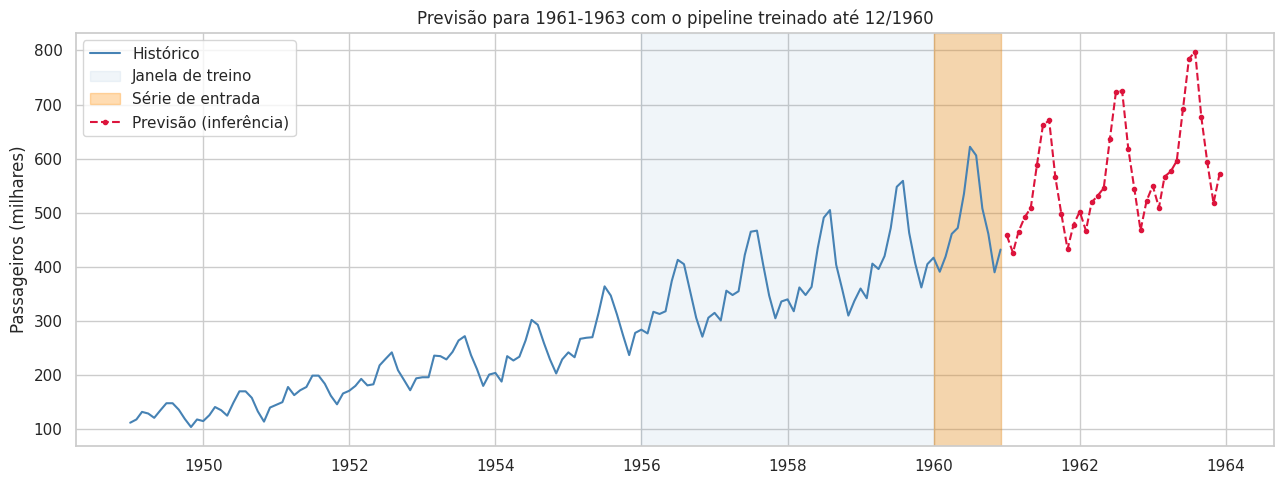

In [ ]:
modelo_producao = treinar(serie, RandomForestRegressor(n_estimators=300, random_state=SEMENTE), janela_treino=60)
entrada_producao = serie.iloc[-12:]
df_futuro = prever(modelo_producao, entrada_producao, h=36)

print(f"Janela de treino : {modelo_producao['inicio_janela']:%m/%Y} a {modelo_producao['fim_janela']:%m/%Y}")
print(f"Série de entrada : {entrada_producao.index[0]:%m/%Y} a {entrada_producao.index[-1]:%m/%Y}")
print(f"Previsão         : {df_futuro.index[0]:%m/%Y} a {df_futuro.index[-1]:%m/%Y}")

plt.figure(figsize=(13, 5))
plt.plot(serie, color="steelblue", label="Histórico")
plt.axvspan(modelo_producao["inicio_janela"], modelo_producao["fim_janela"], color="steelblue", alpha=0.08, label="Janela de treino")
plt.axvspan(entrada_producao.index[0], entrada_producao.index[-1], color="darkorange", alpha=0.3, label="Série de entrada")
plt.plot(df_futuro["previsao"], color="crimson", linestyle="--", marker="o", markersize=3, label="Previsão (inferência)")
plt.title("Previsão para 1961-1963 com o pipeline treinado até 12/1960")
plt.ylabel("Passageiros (milhares)"); plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** Este é o desenho de um sistema real: um **treino** periódico (por exemplo, a cada ano ou trimestre, com a janela escolhida) e uma **inferência** frequente (todo mês, com os 12 meses mais recentes como entrada). Duas observações de honestidade: (1) a regressão devolve **um número por mês, sem intervalo de confiança**: se o diretor precisa de uma faixa de risco, o SARIMA entrega isso de graça (Módulo 8); (2) toda previsão supõe que **o padrão histórico continua valendo**, e não conhece choques externos.

## 10.6 O pipeline completo: do `import` ao salvamento do modelo

Por fim, o bloco abaixo reúne **tudo em um único script**, na ordem em que ele seria executado em um projeto real. Ele não depende de nenhuma variável criada nos módulos anteriores: dá para copiá-lo para um arquivo `.py`. Os dados vêm direto de um **dataset público** (os mesmos passageiros aéreos da aula, hospedados no GitHub), então é preciso estar conectado à internet.

| Etapa | O que faz |
|---|---|
| 1. Imports | Todas as bibliotecas usadas |
| 2. Configuração | Os parâmetros que você muda sem mexer no resto: lags, tamanho da janela de treino, horizonte |
| 3. Dados | Carrega a série de uma **URL pública** com `pd.read_csv` (no seu projeto, troque pela sua fonte) |
| 4. De série para tabela | `montar_atributos` e o `Pipeline` do scikit-learn (Módulo 5) |
| 5. Treino e inferência | As funções `treinar` e `prever` (Módulo 10.2) |
| 6. Validar antes de salvar | Treina sem os últimos 24 meses e confere o erro contra o que aconteceu |
| 7. Treino final e salvamento | Treina com **todo** o histórico e grava o modelo em disco com `joblib` |

In [ ]:
# ==========================================================================================
# PIPELINE COMPLETO: do import ao salvamento do modelo
# ==========================================================================================

# ---------------------------------------- 1. IMPORTS ----------------------------------------
import numpy as np
import pandas as pd
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ------------------------------------- 2. CONFIGURACAO --------------------------------------
LAGS = (1, 2, 3, 12)                       # janela de atributos: ate quantos meses para tras cada previsao olha
JANELA_TREINO = 60                         # janela de treino: ultimos 60 meses (None = historia inteira)
HORIZONTE = 24                             # quantos meses a frente prever
SEMENTE = 42
CAMINHO_MODELO = "modelo_passageiros.joblib"

# ----------------------------------------- 3. DADOS -----------------------------------------
# Dataset publico (Box & Jenkins): passageiros aereos internacionais por mes, 1949-1960
URL_DADOS = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

def carregar_serie():
    df = pd.read_csv(URL_DADOS, index_col="Month", parse_dates=True)      # colunas: Month, Passengers
    return df["Passengers"].asfreq("MS").rename("passageiros")            # indice mensal (MS = inicio de cada mes)

# -------------------------------- 4. DE SERIE PARA TABELA DE LAGS ---------------------------
def montar_atributos(s, lags=LAGS):
    tabela = pd.DataFrame({"y": s})
    for lag in lags:
        tabela[f"lag_{lag}"] = s.shift(lag)            # o passado fica ao lado do presente
    tabela["mes"] = s.index.month                       # calendario: ajuda a reconhecer a sazonalidade
    return tabela.dropna()

def colunas_atributos(lags=LAGS):
    return [f"lag_{lag}" for lag in lags] + ["mes"]

def construir_pipeline(modelo, lags=LAGS):
    preparo = ColumnTransformer([
        ("mes", OneHotEncoder(handle_unknown="ignore"), ["mes"]),
        ("lags", StandardScaler(), [f"lag_{lag}" for lag in lags]),
    ])
    return Pipeline([("preparo", preparo), ("modelo", modelo)])

# ------------------------------------ 5. TREINO E INFERENCIA --------------------------------
def meses_desde(datas, origem):
    return (datas.year - origem.year) * 12 + (datas.month - origem.month)

def treinar(serie, modelo, lags=LAGS, janela_treino=None):
    janela = serie if janela_treino is None else serie.iloc[-janela_treino:]            # peca 1: janela de treino
    origem = janela.index[0]
    log_janela = np.log(janela)
    meses = meses_desde(log_janela.index, origem)
    coef_tendencia = np.polyfit(meses, log_janela.values, 1)
    residuo = log_janela - np.polyval(coef_tendencia, meses)
    df_treino = montar_atributos(residuo, lags)
    pipeline = construir_pipeline(clone(modelo), lags).fit(df_treino[colunas_atributos(lags)], df_treino["y"])
    return {"pipeline": pipeline, "coef_tendencia": coef_tendencia, "origem": origem, "lags": lags,
            "inicio_janela": janela.index[0], "fim_janela": janela.index[-1], "n_linhas_treino": len(df_treino)}

def prever(modelo_treinado, serie_entrada, h):
    lags, coef, origem = modelo_treinado["lags"], modelo_treinado["coef_tendencia"], modelo_treinado["origem"]
    if len(serie_entrada) < max(lags):                                                  # peca 2: serie de entrada
        raise ValueError(f"A serie de entrada precisa ter pelo menos {max(lags)} meses.")
    log_entrada = np.log(serie_entrada)
    df = pd.DataFrame({"residuo": log_entrada - np.polyval(coef, meses_desde(log_entrada.index, origem))}).iloc[-max(lags):]
    datas = pd.date_range(serie_entrada.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    for data in datas:                                                                  # peca 3: inferencia recursiva
        linha = {f"lag_{lag}": df["residuo"].iloc[-lag] for lag in lags}
        linha["mes"] = data.month
        df.loc[data, "residuo"] = modelo_treinado["pipeline"].predict(pd.DataFrame([linha])[colunas_atributos(lags)])[0]
    df_previsao = df.loc[datas].copy()
    df_previsao["tendencia"] = np.polyval(coef, meses_desde(df_previsao.index, origem))
    df_previsao["previsao"] = np.exp(df_previsao["residuo"] + df_previsao["tendencia"])
    return df_previsao

# ------------------------------- 6. VALIDAR ANTES DE SALVAR ---------------------------------
serie_completa = carregar_serie()
historico_validacao, gabarito = serie_completa.iloc[:-HORIZONTE], serie_completa.iloc[-HORIZONTE:]

modelo_validacao = treinar(historico_validacao, RandomForestRegressor(n_estimators=300, random_state=SEMENTE),
                           lags=LAGS, janela_treino=JANELA_TREINO)
df_validacao = prever(modelo_validacao, historico_validacao.iloc[-max(LAGS):], HORIZONTE)
mape_validacao = np.mean(np.abs((gabarito.values - df_validacao["previsao"].values) / gabarito.values)) * 100
print(f"Validação: treinado até {modelo_validacao['fim_janela']:%m/%Y}, erro médio nos {HORIZONTE} meses seguintes = {mape_validacao:.2f}%")

# ------------------------- 7. TREINO FINAL E SALVAMENTO DO MODELO ---------------------------
modelo_final = treinar(serie_completa, RandomForestRegressor(n_estimators=300, random_state=SEMENTE),
                       lags=LAGS, janela_treino=JANELA_TREINO)
joblib.dump(modelo_final, CAMINHO_MODELO)

print(f"Treino final: janela de {modelo_final['inicio_janela']:%m/%Y} a {modelo_final['fim_janela']:%m/%Y} ({modelo_final['n_linhas_treino']} linhas de treino)")
print(f"Modelo salvo em '{CAMINHO_MODELO}'")
# No Colab, para baixar o arquivo para o seu computador:
# from google.colab import files; files.download(CAMINHO_MODELO)

Validação: treinado até 12/1958, erro médio nos 24 meses seguintes = 4.30%
Treino final: janela de 01/1956 a 12/1960 (48 linhas de treino)
Modelo salvo em 'modelo_passageiros.joblib'


> 📌 **Leitura.** Repare na ordem das etapas 6 e 7, que é a de qualquer projeto sério: **primeiro valida** (treina sem o final da série e confere o erro contra o que realmente aconteceu) e **só depois** faz o treino final com todo o histórico e salva. O arquivo gravado guarda o dicionário `modelo_final`: o regressor treinado, a reta de tendência e a janela usada. Para usar o modelo em outro lugar, basta carregá-lo e entregar a **série de entrada**, como mostra a célula abaixo.

> ⚠️ **Aviso técnico.** Como o modelo é um **dicionário** com objetos do scikit-learn e números, ele pode ser carregado em qualquer projeto sem nenhum código extra de classe. Duas condições: usar a **mesma versão do scikit-learn** do treino, e ter a função `prever` (etapa 5) disponível, porque ela é quem sabe fazer a inferência.

In [ ]:
# Recarregando o modelo salvo e usando-o para prever: so precisamos da serie de entrada (os ultimos 12 meses) e do horizonte
modelo_carregado = joblib.load(CAMINHO_MODELO)
entrada_recente = serie_completa.iloc[-12:]

df_previsao_carregado = prever(modelo_carregado, entrada_recente, h=12)
print(f"Previsão de {df_previsao_carregado.index[0]:%m/%Y} a {df_previsao_carregado.index[-1]:%m/%Y}, a partir do modelo salvo:")
df_previsao_carregado[["previsao"]].round(0).rename(columns={"previsao": "passageiros previstos (milhares)"})

Previsão de 01/1961 a 12/1961, a partir do modelo salvo:


,passageiros previstos (milhares)
1961-01-01,458.0
1961-02-01,426.0
1961-03-01,465.0
1961-04-01,492.0
1961-05-01,509.0
1961-06-01,589.0
1961-07-01,662.0
1961-08-01,671.0
1961-09-01,566.0
1961-10-01,498.0


### Plotando os resultados em um bloco separado

O gráfico fica em uma **célula à parte**, que só **usa** o que o pipeline já produziu (`df_validacao`, `df_previsao_carregado` e a série). Assim você refaz ou ajusta o gráfico quantas vezes quiser **sem retreinar nada**. À esquerda, a validação: a previsão contra o que realmente aconteceu. À direita, a previsão feita pelo **modelo salvo**, com a série de entrada destacada.

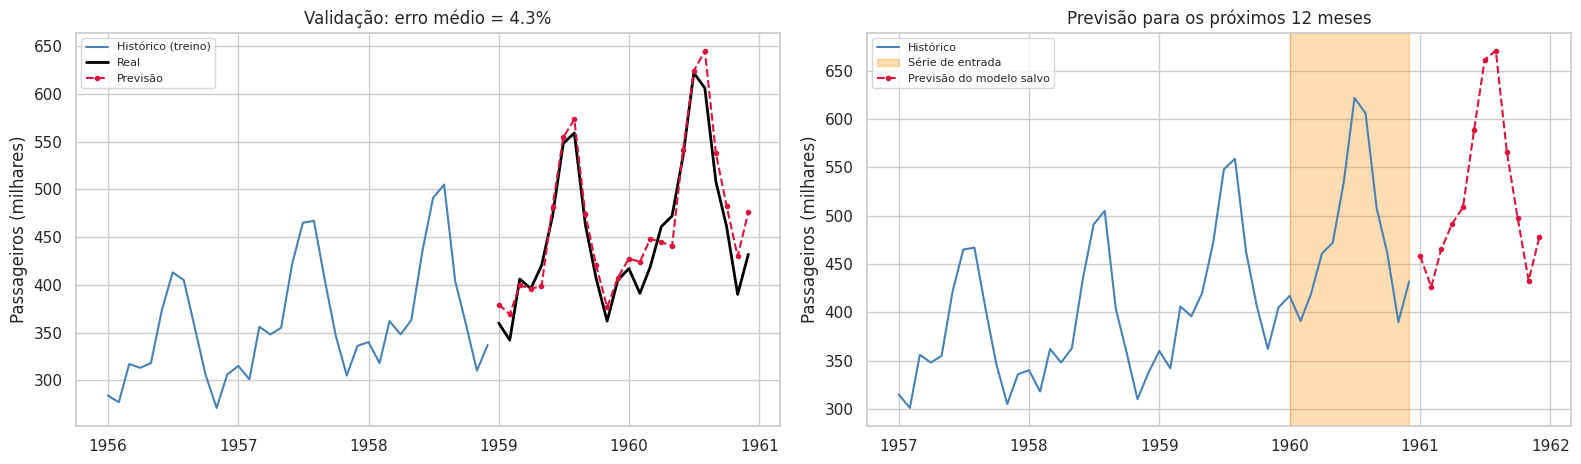

In [ ]:
import matplotlib.pyplot as plt

figura, eixos = plt.subplots(1, 2, figsize=(16, 4.8))

# Grafico 1: VALIDACAO (previsao x o que realmente aconteceu)
eixos[0].plot(historico_validacao.iloc[-36:], color="steelblue", label="Histórico (treino)")
eixos[0].plot(gabarito, color="black", linewidth=2, label="Real")
eixos[0].plot(df_validacao["previsao"], color="crimson", linestyle="--", marker="o", markersize=3, label="Previsão")
eixos[0].set_title(f"Validação: erro médio = {mape_validacao:.1f}%")

# Grafico 2: PREVISAO DO MODELO SALVO (inferencia a partir da serie de entrada)
eixos[1].plot(serie_completa.iloc[-48:], color="steelblue", label="Histórico")
eixos[1].axvspan(entrada_recente.index[0], entrada_recente.index[-1], color="darkorange", alpha=0.3, label="Série de entrada")
eixos[1].plot(df_previsao_carregado["previsao"], color="crimson", linestyle="--", marker="o", markersize=3, label="Previsão do modelo salvo")
eixos[1].set_title("Previsão para os próximos 12 meses")

for eixo in eixos:
    eixo.set_ylabel("Passageiros (milhares)")
    eixo.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 10.7 Explicação linha a linha do pipeline

> ▶️ **Material de consulta.** Esta seção não precisa ser lida em aula: ela explica, **linha a linha**, o bloco do pipeline completo (Seção 10.6), na mesma ordem das 7 etapas. Em cada tabela, a coluna "Por quê" diz o motivo da linha, e não só o que ela faz.

### Etapa 1: imports

| Linha | O que faz | Por quê |
|---|---|---|
| `import numpy as np` | Carrega a biblioteca de contas numéricas | Usada para `log`, `exp` e para ajustar a reta de tendência |
| `import pandas as pd` | Carrega a biblioteca de tabelas | A série, a tabela de lags e a previsão são `Series` e `DataFrame` |
| `import joblib` | Carrega a ferramenta de gravar objetos em arquivo | Usada na etapa 7 para salvar o modelo treinado |
| `from sklearn.base import clone` | Importa a função que copia um modelo **sem o treino** | Cada chamada de `treinar` precisa partir de um modelo "zerado" |
| `from sklearn.compose import ColumnTransformer` | Aplica tratamentos diferentes a colunas diferentes | O mês e os lags precisam de tratamentos distintos |
| `from sklearn.ensemble import RandomForestRegressor` | Importa o regressor usado no exemplo | Pode ser trocado por SVR, Gradient Boosting, Ridge etc. |
| `from sklearn.pipeline import Pipeline` | Encadeia etapas em sequência | Garante que o treino e a previsão passem pelo mesmo preparo dos dados |
| `from sklearn.preprocessing import OneHotEncoder, StandardScaler` | Importa os dois transformadores de dados | O primeiro vira o mês em colunas 0/1; o segundo padroniza os lags |

### Etapa 2: configuração

| Linha | O que faz | Por quê |
|---|---|---|
| `LAGS = (1, 2, 3, 12)` | Define quais atrasos viram colunas da tabela | 1, 2 e 3 meses atrás (o "momento" da série) e 12 meses atrás (o mesmo mês do ano passado). O maior valor, 12, diz quantos meses a série de entrada precisa ter |
| `JANELA_TREINO = 60` | Usa só os últimos 60 meses para treinar | É a janela deslizante do Módulo 10. Com `None`, usaria a história inteira (janela expansiva) |
| `HORIZONTE = 24` | Quantos meses prever | Também é quantos meses ficam reservados para validar na etapa 6 |
| `SEMENTE = 42` | Fixa o sorteio do Random Forest | O modelo sorteia dados e atributos; com a semente fixa, o resultado é sempre o mesmo |
| `CAMINHO_MODELO = "modelo_passageiros.joblib"` | Nome do arquivo onde o modelo será salvo | Fica no topo para ser fácil de mudar |

### Etapa 3: dados

| Linha | O que faz | Por quê |
|---|---|---|
| `URL_DADOS = "https://..."` | Guarda o endereço do arquivo CSV público | Os dados ficam fora do código |
| `def carregar_serie():` | Define uma função que devolve a série pronta | Isola a leitura dos dados: para usar outra fonte, só esta função muda |
| `df = pd.read_csv(URL_DADOS, index_col="Month", parse_dates=True)` | Lê o CSV direto da internet e usa a coluna `Month` como índice | `index_col` transforma `Month` no índice da tabela; `parse_dates=True` converte textos como `1949-01` em datas de verdade |
| `return df["Passengers"]` | Pega só a coluna de passageiros | O resultado é uma `Series`: um valor por mês, indexado por data |
| `.asfreq("MS")` | Declara que a série é mensal, com um ponto no início de cada mês (`MS`) | Garante uma linha por mês, sem buracos, e avisa ao pandas qual é a frequência |
| `.rename("passageiros")` | Dá um nome à série | Só para deixar os resultados mais legíveis |

### Etapa 4: de série para tabela de lags

| Linha | O que faz | Por quê |
|---|---|---|
| `def montar_atributos(s, lags=LAGS):` | Função que recebe uma série `s` e devolve a tabela supervisionada | É a transformação central do Módulo 5 |
| `tabela = pd.DataFrame({"y": s})` | Cria uma tabela com uma coluna `y` | `y` é o **alvo**: o valor do mês que queremos prever |
| `for lag in lags:` | Repete o passo seguinte para cada atraso (1, 2, 3 e 12) | Cada atraso vira uma coluna |
| `tabela[f"lag_{lag}"] = s.shift(lag)` | Cria a coluna `lag_1`, `lag_2`... com a série deslocada `lag` linhas para baixo | O `shift` coloca o passado ao lado do presente: a linha de março fica com o valor de fevereiro em `lag_1`. A f-string `f"lag_{lag}"` monta o nome da coluna |
| `tabela["mes"] = s.index.month` | Cria a coluna com o número do mês (1 a 12), tirado do índice de datas | Ajuda o modelo a reconhecer a sazonalidade |
| `return tabela.dropna()` | Remove as linhas incompletas | As primeiras 12 linhas não têm `lag_12` (valor `NaN`) e não servem para treinar |
| `def colunas_atributos(lags=LAGS):` | Função que lista as colunas de entrada (o `X`) | Evita repetir a lista de nomes em vários lugares |
| `return [f"lag_{lag}" for lag in lags] + ["mes"]` | Monta a lista `["lag_1", "lag_2", "lag_3", "lag_12", "mes"]` | O treino e a previsão precisam usar **exatamente as mesmas colunas, na mesma ordem** |
| `def construir_pipeline(modelo, lags=LAGS):` | Função que monta "preparo dos dados + modelo" | O preparo é parte do modelo e acompanha o treino e a previsão |
| `preparo = ColumnTransformer([...])` | Define um tratamento para cada grupo de colunas | Cada item da lista é `(nome, transformador, colunas)` |
| `("mes", OneHotEncoder(handle_unknown="ignore"), ["mes"])` | Transforma o mês em 12 colunas de 0 e 1 | O mês é uma **categoria** (dezembro não é "maior" que janeiro). `handle_unknown="ignore"` evita erro se aparecer um mês que o treino não viu |
| `("lags", StandardScaler(), [f"lag_{lag}" for lag in lags])` | Padroniza as colunas de lag (média 0 e desvio 1) | Indispensável para SVR e útil para Ridge. O Random Forest não precisa, mas não é prejudicado, e assim o pipeline serve para qualquer regressor |
| `return Pipeline([("preparo", preparo), ("modelo", modelo)])` | Encadeia o preparo e o modelo | Ao chamar `fit` ou `predict`, os dados passam primeiro pelo preparo e depois pelo modelo |

### Etapa 5: treino e inferência

**Função auxiliar**

| Linha | O que faz | Por quê |
|---|---|---|
| `def meses_desde(datas, origem):` | Converte datas em "número do mês", contando a partir de `origem` | A reta de tendência precisa de um eixo `x` numérico: 0, 1, 2... |
| `return (datas.year - origem.year) * 12 + (datas.month - origem.month)` | Diferença em meses entre cada data e a origem | Anos de diferença vezes 12, mais a diferença dos meses |

**`treinar`: o treino**

| Linha | O que faz | Por quê |
|---|---|---|
| `def treinar(serie, modelo, lags=LAGS, janela_treino=None):` | Recebe a série e o regressor, e devolve o modelo treinado | É a fase de "estudar para a prova" |
| `janela = serie if janela_treino is None else serie.iloc[-janela_treino:]` | **Peça 1, a janela de treino.** Usa a série toda ou só os últimos N meses | `iloc[-60:]` pega as últimas 60 linhas |
| `origem = janela.index[0]` | Guarda a data do primeiro mês da janela | É o "tempo zero" da reta de tendência, e a inferência vai precisar dele |
| `log_janela = np.log(janela)` | Passa a série para logaritmo | Estabiliza a oscilação (Módulo 2.3) |
| `meses = meses_desde(log_janela.index, origem)` | Cria o eixo do tempo: 0, 1, 2... | É o `x` da reta |
| `coef_tendencia = np.polyfit(meses, log_janela.values, 1)` | Ajusta uma **reta** (grau 1) ao log da série | Devolve dois números: a inclinação e o ponto de partida. É a tendência |
| `residuo = log_janela - np.polyval(coef_tendencia, meses)` | Subtrai a reta da série | Sobra só o que oscila em torno de zero (sazonalidade e ruído). É por isso que árvores e SVR funcionam bem (Módulo 7) |
| `df_treino = montar_atributos(residuo, lags)` | Transforma o resíduo em tabela de lags | Aplica a transformação do Módulo 5 |
| `pipeline = construir_pipeline(clone(modelo), lags).fit(df_treino[colunas_atributos(lags)], df_treino["y"])` | Monta o pipeline com uma cópia limpa do modelo e **treina** | `clone` evita reaproveitar um treino anterior. `.fit(X, y)` recebe as colunas de entrada (`lags` e `mes`) e o alvo (`y`) |
| `return {"pipeline": ..., "coef_tendencia": ..., ...}` | Devolve um **dicionário** com tudo o que a inferência vai precisar | O modelo treinado, a reta de tendência, a origem do tempo, os lags e as datas da janela. Por ser um dicionário simples, é fácil de salvar |

**`prever`: a inferência**

| Linha | O que faz | Por quê |
|---|---|---|
| `def prever(modelo_treinado, serie_entrada, h):` | Recebe o modelo, a série de entrada e o horizonte `h` | É a fase de "fazer a prova". Note que **não recebe o treino**, só o que foi guardado no dicionário |
| `lags, coef, origem = modelo_treinado["lags"], ...` | Tira do dicionário três itens | Dá nomes curtos para usar adiante |
| `if len(serie_entrada) < max(lags): raise ValueError(...)` | **Peça 2, a série de entrada.** Para com um erro claro se houver menos de 12 meses | Sem 12 meses, não existe `lag_12` para o primeiro mês previsto |
| `log_entrada = np.log(serie_entrada)` | Passa a série de entrada para logaritmo | Precisa receber **o mesmo tratamento** do treino |
| `df = pd.DataFrame({"residuo": log_entrada - np.polyval(coef, meses_desde(log_entrada.index, origem))}).iloc[-max(lags):]` | Tira a tendência da entrada, com **a mesma reta e a mesma origem do treino**, e guarda só os últimos 12 meses em uma tabela de uma coluna | Só os últimos 12 meses importam para os lags. Essa tabela é o "caderno de rascunho" que vai crescer |
| `datas = pd.date_range(serie_entrada.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")` | Cria a lista dos `h` meses futuros, começando no mês seguinte ao último da entrada | `MonthBegin(1)` avança para o primeiro dia do próximo mês |
| `for data in datas:` | **Peça 3, a inferência recursiva.** Percorre os meses futuros um por vez | Cada previsão depende da anterior (o "telefone sem fio") |
| `linha = {f"lag_{lag}": df["residuo"].iloc[-lag] for lag in lags}` | Monta os atributos do mês: `lag_1` é a **última** linha da tabela, `lag_2` a penúltima, `lag_12` a décima segunda de trás para frente | `iloc[-1]` é o último valor, `iloc[-2]` o penúltimo, e assim por diante |
| `linha["mes"] = data.month` | Acrescenta o mês do calendário do mês que vamos prever | O treino também usou a coluna `mes` |
| `df.loc[data, "residuo"] = modelo_treinado["pipeline"].predict(pd.DataFrame([linha])[colunas_atributos(lags)])[0]` | Prevê o mês e **grava a previsão como uma nova linha** da tabela | `pd.DataFrame([linha])` cria uma tabela de uma linha; `[colunas_atributos(lags)]` põe as colunas na mesma ordem do treino; `.predict(...)` devolve uma lista com um número, e `[0]` pega esse número. Como a linha foi gravada em `df`, no próximo mês ela será o `lag_1` |
| `df_previsao = df.loc[datas].copy()` | Separa só as linhas novas, as previsões | A tabela também tinha os 12 meses da entrada, que não queremos devolver |
| `df_previsao["tendencia"] = np.polyval(coef, meses_desde(df_previsao.index, origem))` | Calcula a reta de tendência nos meses futuros | Continua a **mesma reta** do treino para a frente |
| `df_previsao["previsao"] = np.exp(df_previsao["residuo"] + df_previsao["tendencia"])` | Soma a tendência de volta e desfaz o log com `exp` | Devolve o resultado em milhares de passageiros |
| `return df_previsao` | Devolve a tabela com as colunas `residuo`, `tendencia` e `previsao` | Mostra o caminho de cada previsão |

### Etapa 6: validar antes de salvar

| Linha | O que faz | Por quê |
|---|---|---|
| `serie_completa = carregar_serie()` | Carrega a série | Chama a função da etapa 3 |
| `historico_validacao, gabarito = serie_completa.iloc[:-HORIZONTE], serie_completa.iloc[-HORIZONTE:]` | Divide a série em duas partes: tudo **menos** os últimos 24 meses, e **só** os últimos 24 | A primeira é o que o modelo pode ver; a segunda é o "gabarito" escondido. É a divisão temporal do Módulo 3 |
| `modelo_validacao = treinar(historico_validacao, RandomForestRegressor(n_estimators=300, random_state=SEMENTE), ...)` | Treina usando **só** o histórico, com 300 árvores | O modelo não pode enxergar o gabarito. `random_state` fixa o sorteio |
| `df_validacao = prever(modelo_validacao, historico_validacao.iloc[-max(LAGS):], HORIZONTE)` | Prevê 24 meses a partir dos **últimos 12 meses** do histórico | Os últimos 12 meses são a série de entrada |
| `mape_validacao = np.mean(np.abs((gabarito.values - df_validacao["previsao"].values) / gabarito.values)) * 100` | Calcula o erro percentual médio (MAPE) contra o gabarito | Para cada mês, mede o tamanho do erro em % do valor real, e tira a média. `.values` compara por posição, sem depender dos índices |
| `print(f"Validação: ...")` | Mostra o resultado | Na f-string, `:%m/%Y` formata a data como mês/ano e `:.2f` mostra duas casas decimais |

### Etapa 7: treino final e salvamento

| Linha | O que faz | Por quê |
|---|---|---|
| `modelo_final = treinar(serie_completa, RandomForestRegressor(...), ...)` | Treina de novo, agora com **toda** a série | O gabarito já cumpriu o papel de validar. Agora o modelo pode aprender também com os 24 meses mais recentes |
| `joblib.dump(modelo_final, CAMINHO_MODELO)` | Grava o dicionário em arquivo | Depois é só carregar com `joblib.load` e chamar `prever`, sem treinar de novo |
| `print(f"Treino final: ...")` | Mostra a janela de treino e quantas linhas de treino foram usadas | Confirma que a janela de 60 meses virou 48 linhas (60 menos os 12 perdidos no `lag_12`) |
| `print(f"Modelo salvo em '{CAMINHO_MODELO}'")` | Avisa em que arquivo o modelo foi gravado | Confirma que a gravação terminou sem erro |
| `# from google.colab import files; files.download(...)` | Linha comentada que baixa o arquivo no Colab | No Colab, o arquivo fica na máquina virtual e some quando a sessão acaba, então é preciso baixá-lo |

# Módulo 11 — Fechamento

### Checklist do que praticamos
- [ ] Vimos que a ordem importa: embaralhar a série preserva a média, mas destrói a estrutura.
- [ ] Separamos a série em tendência, sazonalidade e resíduo, e decidimos pelo logaritmo.
- [ ] Avaliamos com divisão temporal e comparamos tudo com o naive sazonal.
- [ ] Mostramos por que a regressão "normal" engana (sorteio aleatório e erros com memória).
- [ ] Entendemos **lags, autocorrelação, ACF e PACF**, e **transformamos a série em uma tabela de atributos**.
- [ ] Treinamos **SVR, Random Forest e Gradient Boosting** sobre os lags e vimos o "telefone sem fio" da previsão recursiva.
- [ ] Corrigimos o problema da tendência removendo-a antes.
- [ ] Conhecemos SARIMA e Holt-Winters como alternativas, com intervalo de confiança.
- [ ] Montamos um **pipeline de treino e inferência** e comparamos **janela expansiva x deslizante**.

### Resumo mental

| Pergunta | Resposta prática |
|---|---|
| Como uso um regressor em uma série? | Transforme a série em tabela: alvo = valor do mês; atributos = lags (recentes + sazonal) + mês. |
| Como escolho os lags? | Comece com os recentes (1 a 3) e o sazonal (12), olhando ACF/PACF, e teste variações. |
| Como separo treino e teste? | Sempre pelo tempo: o teste é o final. |
| Meu atributo vaza? | Se usa o presente ou o futuro, sim. `shift` antes de `rolling`. |
| Vou prever vários meses. E agora? | Use previsão **recursiva** e avalie nela, não só em um passo à frente. |
| Modelo de árvore ou SVR com tendência? | Remova a tendência antes (ou use diferenças). |
| Quanto histórico usar no treino? | É um hiperparâmetro: teste janelas (toda a história x últimos N meses) com origem móvel. |
| O que a inferência precisa? | O modelo treinado e a **série de entrada** (os últimos meses conhecidos, no mínimo o maior lag). |
| Qual o piso de qualidade? | O naive sazonal (repetir o ano passado). |
| Meu erro está bom demais? | Suspeite de vazamento. |

## Exercícios

### Exercício 1 — Qual o melhor tamanho de janela?

Para o Random Forest, compare janelas de treino de **36, 48, 60, 84 meses e a história inteira**, usando a função `mape_origem_movel`. Qual tamanho vence? O que acontece com as janelas muito curtas?

In [ ]:
# TODO: para cada tamanho em [36, 48, 60, 84, None], calcule
# mape_origem_movel(RandomForestRegressor(n_estimators=300, random_state=SEMENTE), tamanho)
# e plote um grafico de barras com os resultados.

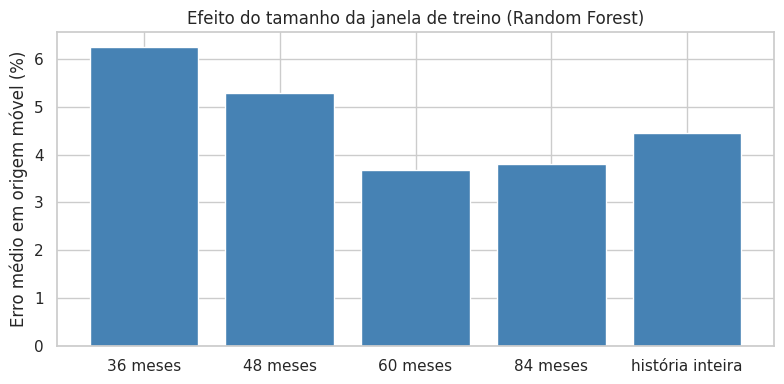

,0
36 meses,6.25
48 meses,5.30
60 meses,3.68
84 meses,3.80
história inteira,4.45


In [ ]:
#@title 🔒 Gabarito — Exercício 1 { display-mode: "form" }
tamanhos = [36, 48, 60, 84, None]
erros = {("história inteira" if t is None else f"{t} meses"): mape_origem_movel(RandomForestRegressor(n_estimators=300, random_state=SEMENTE), t) for t in tamanhos}

plt.figure(figsize=(8, 4))
plt.bar(erros.keys(), erros.values(), color="steelblue")
plt.ylabel("Erro médio em origem móvel (%)"); plt.title("Efeito do tamanho da janela de treino (Random Forest)")
plt.tight_layout()
plt.show()
pd.Series(erros).round(2)

# Esperado: janelas muito curtas (36 meses) tendem a piorar, pois ha poucos ciclos anuais para aprender
# a sazonalidade; a historia inteira tambem fica atras, porque uma unica reta de tendencia serve mal
# para o periodo todo. O melhor tamanho fica no meio, o que e' tipico de um hiperparametro.

### Exercício 2 — Mais memória para o modelo

O pipeline usou os lags `(1, 2, 3, 12)`. Teste `(1, 12)`, `(1, 2, 3, 6, 12)` e `(1, 2, 3, 6, 9, 12)` com o **Ridge** e a janela deslizante de 60 meses, em origem móvel, e compare.

In [ ]:
# TODO: para cada conjunto de lags, calcule
# mape_origem_movel(Ridge(alpha=0.1), 60, lags=conjunto) e compare.

In [ ]:
#@title 🔒 Gabarito — Exercício 2 { display-mode: "form" }
resultado = {str(l): mape_origem_movel(Ridge(alpha=0.1), 60, lags=l) for l in [(1, 12), (1, 2, 3, 12), (1, 2, 3, 6, 12), (1, 2, 3, 6, 9, 12)]}
pd.Series(resultado, name="erro % em origem móvel").round(2)

# Esperado: as diferencas costumam ser pequenas. Mais lags = mais atributos e menos linhas de treino
# (cada lag extra "come" uma linha), e na previsao recursiva cada lag extra tambem carrega erro acumulado.
# Teste sempre em varios cortes antes de concluir que um conjunto de lags e' melhor.

,erro % em origem móvel
"(1, 12)",3.34
"(1, 2, 3, 12)",3.35
"(1, 2, 3, 6, 12)",3.38
"(1, 2, 3, 6, 9, 12)",3.54


### Para ir além

1. **Escolher a janela no tempo.** Use `TimeSeriesSplit` para escolher **automaticamente** o tamanho da janela de treino (e o `alpha` do Ridge), em vez de testar à mão.
2. **Variáveis externas.** Acrescente colunas à tabela (feriados, preço, temperatura). É uma das grandes vantagens da regressão com lags sobre os modelos clássicos.
3. **Previsão direta.** Em vez de recursiva, treine um modelo **por horizonte** e compare com o telefone sem fio do Módulo 6.
4. **Intervalos para a regressão.** Use regressão quantílica (`GradientBoostingRegressor(loss="quantile")`) ou *bootstrap* dos resíduos para obter faixas de previsão.
5. **Outras métricas e modelos.** MASE (erro relativo ao naive sazonal), `Prophet`, `LightGBM` com lags, redes recorrentes. Todos obedecem às mesmas regras de validação temporal.
6. **Anomalias em séries.** Os resíduos do SARIMA servem de entrada para detectores de anomalia: meses em que o real fugiu muito do previsto.

### Referência

- Box, G. E. P., Jenkins, G. M. e Reinsel, G. C. *Time Series Analysis: Forecasting and Control*. Série G: passageiros mensais de companhias aéreas internacionais, 1949 a 1960.
- Hyndman, R. J. e Athanasopoulos, G. *Forecasting: Principles and Practice* (3ª ed.). OTexts. Disponível gratuitamente em https://otexts.com/fpp3/.